# HW1 — Predicting Paddy Yield with Linear Regression
**FRA503 Introduction to Machine Learning (1/2569)**

*Phattanarat Jeedjeen 68340700410*

---


## Table of contents
- [1. Problem statement](#1--problem-statement)
- [2. Data loading & quality audit](#2--data-loading--quality-audit)
- [3. Train / test split](#3--train--test-split)
- [4. Target distribution](#4--target-distribution)
- [5. Initial feature exploration](#5--initial-feature-exploration)
- [6. Outlier analysis](#6--outlier-analysis)
- [7. Missing-value analysis](#7--missing-value-analysis)
- [8. Feature selection — continuous features](#8--feature-selection--continuous-features)
- [9. Feature selection — categorical features](#9--feature-selection--categorical-features)
- [10. Redundant-feature analysis](#10--redundant-feature-analysis)
- [11. Feature extraction](#11--feature-extraction)
- [12. Data pre-processing for ML](#12--data-pre-processing-for-ml)
- [13. Target transformation](#13--target-transformation)
- [14. Model building & training](#14--model-building-and-training)
- [15. Results and presentation](#15--results-and-presentation)
- [16. Discussion](#16--discussion)
- [17. Conclusion](#17--conclusion)

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

SEED = 42
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 60); pd.set_option('display.max_rows', 100)
def _fmt(v):
    if v != v: return 'nan'
    if v == 0: return '0'
    if abs(v) < 1e-4: return f'{v:.2e}'
    if abs(v) >= 1e5: return f'{v:,.0f}'
    return f'{v:,.4f}'.rstrip('0').rstrip('.') if abs(v) < 1000 else f'{v:,.2f}'.rstrip('0').rstrip('.')
pd.set_option('display.float_format', _fmt)

BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREY, INK = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#8a8a85', '#0b0b0b'
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e4e3de', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.prop_cycle': plt.cycler(color=[BLUE, ORANGE, AQUA, YELLOW, MAGENTA]),
    'axes.titlesize': 10, 'axes.labelsize': 9, 'xtick.labelsize': 8, 'ytick.labelsize': 8,
    'legend.frameon': False, 'legend.fontsize': 8, 'figure.autolayout': False})
print('setup ok  | numpy', np.__version__, '| pandas', pd.__version__)

setup ok  | numpy 1.26.4 | pandas 2.1.4


In [2]:
from scipy import stats

def regression_metrics(y_true, y_pred):
    """R2 = 1 - SSR/SST, RMSE, MAE, MAPE."""
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    res = y_true - y_pred
    ssr, sst = (res**2).sum(), ((y_true - y_true.mean())**2).sum()
    return dict(R2=1 - ssr / sst, RMSE=np.sqrt(np.mean(res**2)), MAE=np.abs(res).mean(), MAPE=100 * np.mean(np.abs(res / y_true)))

# 1 · Problem statement

### 1.1 Data description
**Paddy dataset** (UCI ML Repository, DOI 10.24432/C55W3J, CC BY 4.0) describes rice cultivation: plot size, agri-block, variety, soil type, nursery type, seed rate, land-preparation inputs, fertiliser/herbicide/pesticide amounts applied on given days, rainfall and an "AI" variable per growth window, min/max temperature, wind speed/direction and humidity per 30-day window, `Trash` count, and `Paddy yield`. UCI reports 2,790 instances × 45 columns with *no missing values*. 

## Variable description
| # | Feature | Type | Definition |
|---|---|---|---|
| 1 | `Hectares` | Numerical (Integer) | Plot size, in hectares |
| 2 | `Agriblock` | Categorical | Agricultural block / district where the plot is located |
| 3 | `Variety` | Categorical | Rice variety planted, e.g. CO_43, ponmani, delux ponni |
| 4 | `Soil Types` | Categorical | Soil type, e.g. alluvial or clay |
| 5 | `Seedrate (in Kg)` | Numerical (Integer) | Seed quantity used, in kg |
| 6 | `LP_Mainfield (in Tonnes)` | Numerical (Continuous) | Land-preparation material/manure used in the main field, in tonnes; exact material not specified |
| 7 | `Nursery` | Categorical | Nursery preparation method, e.g. dry or wet |
| 8 | `Nursery area (Cents)` | Numerical (Integer) | Nursery area, in cents |
| 9 | `LP_nurseryarea (in Tonnes)` | Numerical (Integer) | Manure used to prepare the nursery area, in tonnes |
| 10 | `DAP_20days` | Numerical (Integer) | DAP fertiliser applied around day 20 |
| 11 | `Weed28D_thiobencarb` | Numerical | Thiobencarb herbicide applied around day 28 |
| 12 | `Urea_40Days` | Numerical (Continuous) | Urea fertiliser applied around day 40 |
| 13 | `Potassh_50Days` | Numerical (Continuous) | Potash/potassium fertiliser applied around day 50 |
| 14 | `Micronutrients_70Days` | Numerical | Micronutrients applied around day 70 |
| 15 | `Pest_60Day (in ml)` | Numerical | Pesticide applied around day 60, in ml |
| 16 | `30DRain (in mm)` | Numerical (Continuous) | Rainfall in roughly the first 30 days, in mm |
| 17 | `30DAI (in mm)` | Numerical (Continuous) | "AI" variable for the first 30 days, in mm; not defined by the source |
| 18 | `30_50DRain (in mm)` | Numerical (Continuous) | Rainfall on days 30-50, in mm |
| 19 | `30_50DAI (in mm)` | Numerical (Continuous) | "AI" for days 30-50, in mm; undefined |
| 20 | `51_70DRain (in mm)` | Numerical (Continuous) | Rainfall on days 51-70, in mm |
| 21 | `51_70AI (in mm)` | Numerical (Continuous) | "AI" for days 51-70, in mm; undefined |
| 22 | `71_105DRain (in mm)` | Numerical (Continuous) | Rainfall on days 71-105, in mm |
| 23 | `71_105DAI (in mm)` | Numerical (Continuous) | "AI" for days 71-105, in mm; undefined |
| 24 | `Min temp_D1_D30` | Numerical (Continuous) | Minimum temperature, days 1-30 |
| 25 | `Max temp_D1_D30` | Numerical (Continuous) | Maximum temperature, days 1-30 |
| 26 | `Min temp_D31_D60` | Numerical (Continuous) | Minimum temperature, days 31-60 |
| 27 | `Max temp_D31_D60` | Numerical (Continuous) | Maximum temperature, days 31-60 |
| 28 | `Min temp_D61_D90` | Numerical (Continuous) | Minimum temperature, days 61-90 |
| 29 | `Max temp_D61_D90` | Numerical (Continuous) | Maximum temperature, days 61-90 |
| 30 | `Min temp_D91_D120` | Numerical (Continuous) | Minimum temperature, days 91-120 |
| 31 | `Max temp_D91_D120` | Numerical (Continuous) | Maximum temperature, days 91-120 |
| 32 | `Inst Wind Speed_D1_D30 (in Knots)` | Numerical | Instantaneous wind speed, days 1-30, in knots |
| 33 | `Inst Wind Speed_D31_D60 (in Knots)` | Numerical | Instantaneous wind speed, days 31-60, in knots |
| 34 | `Inst Wind Speed_D61_D90 (in Knots)` | Numerical | Instantaneous wind speed, days 61-90, in knots |
| 35 | `Inst Wind Speed_D91_D120 (in Knots)` | Numerical | Instantaneous wind speed, days 91-120, in knots |
| 36 | `Wind Direction_D1_D30` | Categorical | Wind direction, days 1-30, e.g. SW, NW, ENE, W |
| 37 | `Wind Direction_D31_D60` | Categorical | Wind direction, days 31-60 |
| 38 | `Wind Direction_D61_D90` | Categorical | Wind direction, days 61-90 |
| 39 | `Wind Direction_D91_D120` | Categorical | Wind direction, days 91-120 |
| 40 | `Relative Humidity_D1_D30` | Numerical (Continuous) | Relative humidity, days 1-30 |
| 41 | `Relative Humidity_D31_D60` | Numerical (Continuous) | Relative humidity, days 31-60 |
| 42 | `Relative Humidity_D61_D90` | Numerical (Continuous) | Relative humidity, days 61-90 |
| 43 | `Relative Humidity_D91_D120` | Numerical (Continuous) | Relative humidity, days 91-120 |
| 44 | `Trash (in bundles)` | Numerical (Integer) | Quantity of "Trash", measured in bundles; the exact material is not specified |
| 45 | `Paddy yield (in Kg)` | Numerical (Integer) | Total paddy yield, in kg |

### 1.2 Problem definition
| Topic | Definition |
|---|---|
| **General problem** | Farmers want to know how many kg a given plot will yield, based on what's known about the plot, cultivation practices, and weather, to plan harvest, storage and sales. |
| **ML problem** | **Supervised regression** (continuous target). Learn $f:\mathbf{x}\rightarrow \hat y$ with **linear regression**, minimising $\lVert X\mathbf a-\mathbf y\rVert_2^2$, evaluated on unseen data (R², RMSE, MAE, MAPE). |
| **Target variable** | `Paddy yield(in Kg)` — total yield per plot, A derived view, **yield per hectare** (= yield / Hectares), is used later only as a diagnostic. |
| **Predictors (candidates)** | The remaining 44 columns, minus whatever the leakage audit below removes. |
| **Sample** | One row = one season's cultivation record for one plot (1-6 ha) in one of 6 agri-blocks. |

### 1.3 Assumptions (each tested or discussed later)
| # | Assumption | Why it matters |
|---|---|---|
| A1 | **Prediction time = end of the ~120-day growth cycle**, just before yield is weighed; all inputs and all 4 weather windows are known by then | Determines which columns are *available* at prediction time; anything not yet known is leakage |
| A2 | Rows are independent plots (no plot ID, date or year, so repeated measures / time order can't be checked) | linear regression and K-fold CV assume independent observations |
| A3 | Weather columns are block-level summaries, not per-plot measurements | Otherwise weather would be a plot-level feature |
| A4 | `AI` is undocumented; treated as an available but unexplained seasonal variable until the data says more | Can't include/exclude on documentation alone |
| A5 | Rows are treated as records of real plots. The inputs (seed, fertiliser, pesticide amounts) may simply scale with plot area, as they would if farmers followed a fixed per-hectare recommendation, or if the data were generated from one | If true, results describe this dataset and may not generalise to real farms |

### 1.4 Data-leakage audit — which predictors are usable
**Target leakage** = a predictor that carries information about the target that won't be available at prediction time, inflating test scores while failing in practice. The audit below runs before modelling, using domain reasoning (A1) alone; empirical evidence is added later.

| Column | Decision | Reason |
|---|---|---|
| `Paddy yield(in Kg)` | target | — |
| **`Trash(in bundles)`** | dropped (leakage) | Trash is a threshing by-product (straw/husk bundles) counted at harvest — the same moment yield is weighed. It doesn't exist at prediction time (A1); using it is like predicting an outcome from another by-product of the same event. |
| `Hectares`, `Agriblock`, `Variety`, `Soil Types`, `Nursery` | candidate | fixed before planting |
| `Seedrate`, `LP_Mainfield`, `Nursery area`, `LP_nurseryarea`, `DAP_20days`, `Weed28D_thiobencarb`, `Urea_40Days`, `Potassh_50Days`, `Micronutrients_70Days`, `Pest_60Day` | candidate | decisions made during the season, all pre-harvest (A1); possible redundancy examined later |
| `30DRain … 71_105DRain`, `*AI`, temperature, wind speed/direction, humidity (D1-D120) | candidate under A1 only | The *last* window's weather (D91-D120, days 71-105) is only known near harvest. It's not leakage for an end-of-season estimate (weather causes yield, it isn't a by-product of it), but it wouldn't be available for an early-season forecast — that use case would need to drop all in-season weather and inputs |
| yield per hectare (derived) | never a predictor | used only as an alternative target |

**Other leakage**
1. *Pre-processing leakage* — scalers, PCA, encoders and every selection statistic are **fit on training rows only**
2. *Duplicate leakage* — exact duplicate rows are removed **before** the split
3. *Selection leakage* — correlation/ANOVA/MI/chi-square statistics are computed on the **training set only**
4. *Group leakage* — weather is identical for every plot in the same agri-block, so a random split lets the model see that block's weather during training. A cross-validation by agri-block (train on 5 blocks, validate on the 6th) is reported as well.

# 2 · Data loading & quality audit
Quality is checked across 6 dimensions — **Accurate, Complete, Consistent, Valid, Uniform, Unique**.

In [3]:
from pathlib import Path

DATA_PATH = Path('~/paddy/dataset/paddydataset.csv').expanduser()
raw = pd.read_csv(DATA_PATH, encoding='latin')
print('Shape as read:', raw.shape)
bad_names = [repr(c) for c in raw.columns if c != c.strip()]
print('Column names with stray whitespace:', bad_names)
raw.columns = raw.columns.str.strip()          # 'Hectares ' -> 'Hectares'
raw.head(5)

Shape as read: (2789, 45)
Column names with stray whitespace: ["'Hectares '"]


,Hectares,Agriblock,Variety,Soil Types,Seedrate(in Kg),LP_Mainfield(in Tonnes),Nursery,Nursery area (Cents),LP_nurseryarea(in Tonnes),DAP_20days,Weed28D_thiobencarb,Urea_40Days,Potassh_50Days,Micronutrients_70Days,Pest_60Day(in ml),30DRain( in mm),30DAI(in mm),30_50DRain( in mm),30_50DAI(in mm),51_70DRain(in mm),51_70AI(in mm),71_105DRain(in mm),71_105DAI(in mm),Min temp_D1_D30,Max temp_D1_D30,Min temp_D31_D60,Max temp_D31_D60,Min temp_D61_D90,Max temp_D61_D90,Min temp_D91_D120,Max temp_D91_D120,Inst Wind Speed_D1_D30(in Knots),Inst Wind Speed_D31_D60(in Knots),Inst Wind Speed_D61_D90(in Knots),Inst Wind Speed_D91_D120(in Knots),Wind Direction_D1_D30,Wind Direction_D31_D60,Wind Direction_D61_D90,Wind Direction_D91_D120,Relative Humidity_D1_D30,Relative Humidity_D31_D60,Relative Humidity_D61_D90,Relative Humidity_D91_D120,Trash(in bundles),Paddy yield(in Kg)
0,6,Cuddalore,CO_43,alluvial,150,75,dry,120,6,240,12,162.78,62.28,90,3600,19.6,20.4,187.2,270.8,167,250,61,64,18.5,34,16,30,15.5,31,16,33,4,10,8,10,SW,W,NNW,WSW,72,78,88,85,540,35028
1,6,Kurinjipadi,ponmani,clay,150,75,wet,120,6,240,12,162.78,62.28,90,3600,19.6,20.4,187.2,270.8,167,250,61,64,19.5,34,18.5,35,17,32.5,16,30.5,10,4,10,6,NW,S,SE,SSE,64.6,85,84,87,600,35412
2,6,Panruti,delux ponni,alluvial,150,75,dry,120,6,240,12,162.78,62.28,90,3600,18.5,21.5,185.2,272.8,165.3,251.7,60,65,20,35,18,30,17.5,33.5,18,33,4,12,4,12,ENE,NE,NNE,W,85,96,84,79,600,36300
3,6,Kallakurichi,CO_43,clay,150,75,wet,120,6,240,12,162.78,62.28,90,3600,18.5,21.5,185.2,272.8,165.3,251.7,60,65,19,33,17,32,16.5,31.5,15.5,32.5,8,6,8,6,W,WNW,SE,S,88.5,95,81,84,540,35016
4,6,Sankarapuram,ponmani,alluvial,150,75,dry,120,6,240,12,162.78,62.28,90,3600,18.1,21.9,185.6,272.4,166.1,250.9,60.2,64.8,20.5,32,17.5,28,18,34,16.5,35,10,12,10,12,SSE,W,SW,NW,72.7,91,83,81,600,34044


In [4]:
# ---- Column groups used throughout (names checked against the actual file) ----
Y = 'Paddy yield(in Kg)'
PER = ['D1_D30', 'D31_D60', 'D61_D90', 'D91_D120']
CAT = ['Agriblock', 'Variety', 'Soil Types', 'Nursery'] + [f'Wind Direction_{p}' for p in PER]
INPUTS = ['Seedrate(in Kg)', 'LP_Mainfield(in Tonnes)', 'Nursery area (Cents)', 'LP_nurseryarea(in Tonnes)', 'DAP_20days',
          'Weed28D_thiobencarb', 'Urea_40Days', 'Potassh_50Days', 'Micronutrients_70Days', 'Pest_60Day(in ml)']
RAIN = ['30DRain( in mm)', '30_50DRain( in mm)', '51_70DRain(in mm)', '71_105DRain(in mm)']
AI   = ['30DAI(in mm)', '30_50DAI(in mm)', '51_70AI(in mm)', '71_105DAI(in mm)']
TMIN = [f'Min temp_{p}' for p in PER]; TMAX = [f'Max temp_{p}' for p in PER]
WIND = [f'Inst Wind Speed_{p}(in Knots)' for p in PER]; RH = [f'Relative Humidity_{p}' for p in PER]
TRASH = 'Trash(in bundles)'
NUM = ['Hectares'] + INPUTS + RAIN + AI + TMIN + TMAX + WIND + RH + [TRASH]     # 36 numeric predictors (incl. Trash, kept for the audit only)
assert set(NUM + CAT + [Y]) == set(raw.columns) and len(NUM + CAT + [Y]) == raw.shape[1] == 45
print('numeric predictors:', len(NUM), '| categorical predictors:', len(CAT), '| target: 1')

numeric predictors: 36 | categorical predictors: 8 | target: 1


In [5]:
# ---- 6-dimension data-quality audit ----
checks = []

# Complete
checks.append(('Complete', 'missing cells', int(raw.isna().sum().sum())))

# Consistent: data types must be uniform within an attribute
obj_cols = raw.select_dtypes('object').columns.tolist()
mixed = [c for c in NUM + [Y] if not pd.api.types.is_numeric_dtype(raw[c])]
checks.append(('Consistent', 'numeric columns stored as text', len(mixed)))
checks.append(('Consistent', 'text columns = the 8 expected categorical', f'{len(obj_cols)} (match={set(obj_cols)==set(CAT)})'))
lab = sum(raw[c].nunique() != raw[c].str.strip().str.lower().nunique() for c in CAT)
checks.append(('Consistent', 'categorical columns with case/space variants of one label', lab))

# Valid: satisfies business rules / physical constraints
tvio = sum((raw[f'Min temp_{p}'] > raw[f'Max temp_{p}']).sum() for p in PER)
checks.append(('Valid', 'rows with Min temp > Max temp', int(tvio)))
checks.append(('Valid', 'relative humidity outside 0-100 %', int(((raw[RH] < 0) | (raw[RH] > 100)).sum().sum())))
neg = int((raw[[c for c in NUM if c not in TMIN + TMAX]] < 0).sum().sum())
checks.append(('Valid', 'negative amounts / areas / rain', neg))
checks.append(('Valid', 'target <= 0', int((raw[Y] <= 0).sum())))

# Accurate / Uniform: no ground truth available -> report the range and how units are labelled
checks.append(('Accurate', 'target range (kg)', f'{raw[Y].min():,.0f} - {raw[Y].max():,.0f}'))
checks.append(('Uniform', 'units', 'stated in column names (Kg, Tonnes, mm, Knots, Cents)'))

# Unique
ndup = int(raw.duplicated().sum())
checks.append(('Unique', 'exact duplicate rows (all 45 columns)', f'{ndup}  ({ndup/len(raw):.1%})'))
pd.DataFrame(checks, columns=['Dimension', 'Check', 'Result'])

,Dimension,Check,Result
0,Complete,missing cells,0
1,Consistent,numeric columns stored as text,0
2,Consistent,text columns = the 8 expected categorical,8 (match=True)
3,Consistent,categorical columns with case/space variants o...,0
4,Valid,rows with Min temp > Max temp,0
5,Valid,relative humidity outside 0-100 %,0
6,Valid,negative amounts / areas / rain,0
7,Valid,target <= 0,0
8,Accurate,target range (kg),"5,410 - 38,814"
9,Uniform,units,"stated in column names (Kg, Tonnes, mm, Knots,..."


**Audit result**
* **Complete:** 0 missing cells.
* **Consistent:** 0 numeric columns stored as text; the 8 text columns match the expected categorical set; 0 columns with case/space variants of one label. One defect was found earlier: the stray space in `'Hectares '` (fixed on load).
* **Valid:** 0 rows with min temp > max temp, 0 humidity values outside 0-100 %, 0 negative amounts/areas/rain, 0 targets <= 0.
* **Accurate / Uniform:** yield range is 5,410-38,814 kg (plausible, but there is no external truth to compare); units are stated in the column names and cannot be verified further.
* **Unique:** 451 exact duplicate rows (16.2 %), examined in the next cell.
* **Decision:** keep all columns as they are; deal with the duplicates below.


In [6]:
print(f'distinct yield values: {raw[Y].nunique()} across {len(raw)} rows')

distinct yield values: 477 across 2789 rows


**Decision — drop exact duplicates (keep first)**
* *Reason 1 ("Unique"):* a record should appear once; duplicates over-weight some plots in the least-squares sum
* *Reason 2 (leakage):* if a duplicate lands in test while its twin is in train, the model is tested on something it already saw
* *Assumption / risk:* there's no plot ID, so identical rows could be coincidentally-identical distinct plots. Yield has only 477 distinct values across 2,789 rows, so coincidence is plausible, and some real plots may be dropped. Accepted because the alternative (leakage) is worse.


In [7]:
df = raw.drop_duplicates().copy()                # keeps the original row index
print(f'rows: {len(raw)} -> {len(df)}  (removed {len(raw)-len(df)})')

rows: 2789 -> 2338  (removed 451)


### 2.1 Data representation and scale types
This dataset is a **data matrix** $D\in\mathbb{R}^{n\times d}$: $n$ = plots (rows = instances $\mathbf{x}_i$), $d$ = 44 attributes (columns $X_j$) plus target. The table below classifies every attribute. The rough Guideline rule — *"categorical if < 20 unique values and values repeat"* — is combined with domain meaning

In [8]:
def kind_of(c):
    if c in CAT: return ('Qualitative', 'Categorical', 'Nominal (compass direction treated as nominal)' if 'Wind Dir' in c else 'Nominal')
    if c in TMIN + TMAX: return ('Quantitative', 'Continuous', 'Interval (degC: no true zero)')
    if c in RH: return ('Quantitative', 'Continuous', 'Ratio (% of saturation)')
    if c in RAIN + AI + WIND: return ('Quantitative', 'Continuous', 'Ratio')
    if c in ['Hectares', TRASH, 'Seedrate(in Kg)', 'Nursery area (Cents)', 'LP_nurseryarea(in Tonnes)', 'DAP_20days', Y]:
        return ('Quantitative', 'Discrete (integer count / amount)', 'Ratio')
    return ('Quantitative', 'Continuous', 'Ratio')
rep = pd.DataFrame({c: kind_of(c) for c in df.columns}, index=['Type', 'Discrete/Continuous', 'Scale']).T
rep['n_unique'] = df.nunique(); rep['<20 unique?'] = rep.n_unique < 20
print(rep.groupby(['Type', 'Discrete/Continuous', 'Scale']).size().to_string())
print(f"\nQuantitative columns (incl. the target) with < 20 unique values: {int(((rep.Type=='Quantitative') & rep['<20 unique?']).sum())} of {int((rep.Type=='Quantitative').sum())}")

Type          Discrete/Continuous                Scale                                         
Qualitative   Categorical                        Nominal                                            4
                                                 Nominal (compass direction treated as nominal)     4
Quantitative  Continuous                         Interval (degC: no true zero)                      8
                                                 Ratio                                             18
                                                 Ratio (% of saturation)                            4
              Discrete (integer count / amount)  Ratio                                              7

Quantitative columns (incl. the target) with < 20 unique values: 36 of 37


**Effect on the analysis**
* 36 of the 37 quantitative columns (incl. the target) have < 20 unique values. The rule "< 20 unique = categorical" is **not** applied to them: they are measurements, so order and distance matter.

| Scale type | Example columns | Property | Effect here |
|---|---|---|---|
| **Nominal** | block, variety, soil, nursery, wind direction | no order | needs **one-hot encoding**, not integer codes (which would impose a fake order/distance on a linear model) |
| **Ordinal** | none in this set | — | ordinal encoding not needed |
| **Interval** | temperature (°C) | no true zero | ratios are meaningless, only differences are; **standardisation** (not a ratio-based transform like log) is appropriate |
| **Ratio** | area, amounts, rainfall | true zero | **log/cube-root/Box-Cox** transforms make sense if skewed |

# 3 · Train / test split — *before any data-driven analysis* *(leakage guard)*
Every later decision (outlier fences, transforms, correlations, ANOVA, PCA loadings, scaling) *learns from the data*. If test rows influence any of them, test scores are inflated. All exploration below uses **`train` only**

**Method:** random 70/30 split, `random_state=42`.

**Assumptions:** rows are independent (A2); the sample is large enough for both parts to be representative (checked below via train/test target histograms and `Hectares` shares).

train (1636, 45) | test (702, 45)


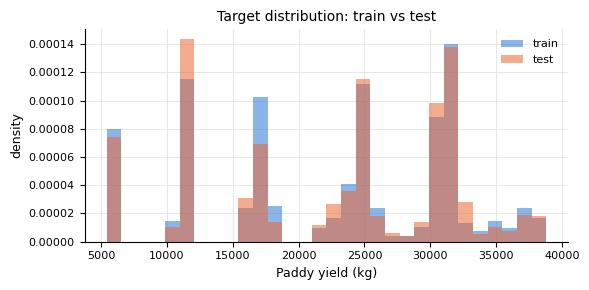

Hectares share (%):
 Hectares   1    2    3    4    5   6
train    8.9 14.5 16.9 22.7 28.5 8.5
test     8.3 17.1 12.7 23.1 31.2 7.7


In [9]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(df, test_size=0.30, random_state=SEED)
print('train', train.shape, '| test', test.shape)
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(train[Y], bins=30, alpha=0.55, color=BLUE, label='train', density=True)
ax.hist(test[Y], bins=30, alpha=0.55, color=ORANGE, label='test', density=True)
ax.set(title='Target distribution: train vs test', xlabel='Paddy yield (kg)', ylabel='density'); ax.legend()
plt.tight_layout(); plt.show()
print('Hectares share (%):\n', pd.concat([train.Hectares.value_counts(normalize=True).sort_index().mul(100).rename('train'),
                                          test.Hectares.value_counts(normalize=True).sort_index().mul(100).rename('test')], axis=1).round(1).T.to_string())

In [10]:
# ---- Amount of leakage if duplicates were kept (same seed, split before removing duplicates) ----
feat_cols = [c for c in raw.columns if c != Y]
rs_tr, rs_te = train_test_split(raw, test_size=0.30, random_state=SEED)
hit = rs_te.merge(rs_tr.drop_duplicates(), how='left', indicator=True)['_merge'].eq('both').mean()
print(f'If duplicates were kept, {hit:.1%} of TEST rows would have an exact copy (all 45 columns) in TRAIN.')

tw = test[feat_cols].merge(train[feat_cols].drop_duplicates(), how='left', indicator=True)['_merge'].eq('both').mean()
print(f'After de-duplication, {tw:.1%} of test rows still share their whole FEATURE vector with some training row '
      '(different yield)')

If duplicates were kept, 25.8% of TEST rows would have an exact copy (all 45 columns) in TRAIN.
After de-duplication, 96.2% of test rows still share their whole FEATURE vector with some training row (different yield)


**Reading:**
* The split is representative — train and test target histograms overlap almost exactly, and `Hectares` shares are close (small differences, e.g. 3 ha: 16.9% vs 12.7%, are expected from randomness).
* Keeping duplicates would have let **25.8%** of test rows be "answered from memory"
* Even after de-duplication, **96.2%** of test feature vectors still have an exact twin in train (different yield)


# 4 · Target distribution
**Checks:** balance, skewness and outliers of the target.

**Tools** (the target is a single continuous variable, so the checks are about its own shape — not yet a relationship with anything else):
* Histogram shows the overall shape.
* The box-plot here is **univariate** (median, spread, points beyond the whiskers of `yy` alone)
* Skewness (0 = symmetric) summarises the asymmetry in one number; it is sensitive to extreme values.

**Plan:** start with the quantity actually modelled later — raw yield in kg. If its shape looks unusual, trace the *cause* using available columns before deciding what (if anything) to do.

,Paddy yield (kg)
count,"1,636"
mean,"22,576.07"
std,"9,257.53"
min,"5,410"
25%,"16,389"
50%,"24,620"
75%,"31,035"
max,"38,814"
skewness,-0.3046


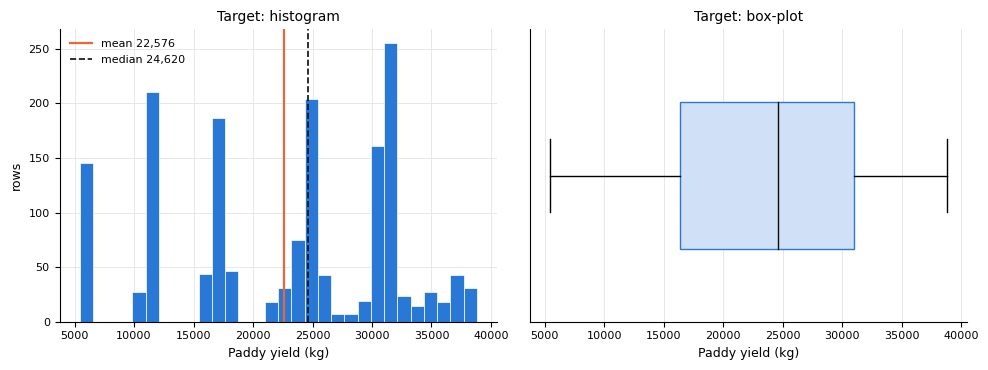

In [11]:
from IPython.display import display

tr = train.copy()                                    # <- all EDA and feature-selection cells from here on use `tr` (train only, never test)
yy = tr[Y]
summ = pd.DataFrame({'Paddy yield (kg)': yy.describe()})
summ.loc['skewness'] = [yy.skew()]
display(summ)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].hist(yy, bins=30, color=BLUE, edgecolor='white', lw=0.5); ax[0].axvline(yy.mean(), color=ORANGE, lw=1.6, label=f'mean {yy.mean():,.0f}')
ax[0].axvline(yy.median(), color=INK, lw=1.2, ls='--', label=f'median {yy.median():,.0f}'); ax[0].legend(); ax[0].set(title='Target: histogram', xlabel='Paddy yield (kg)', ylabel='rows')
ax[1].boxplot(yy, vert=False, whis=1.5, widths=0.5, patch_artist=True, boxprops=dict(facecolor='#cfe0f7', color=BLUE), medianprops=dict(color=INK), flierprops=dict(marker='o', ms=3, mfc=ORANGE, mec=ORANGE))
ax[1].set(title='Target: box-plot', xlabel='Paddy yield (kg)', yticks=[])
plt.tight_layout(); plt.show()

### 4.1 Reading — raw target
* Mean 22,576 kg, median 24,620 kg, SD 9,258 kg, range 5,410-38,814 kg.
* Skewness **-0.30** (slight left skew, within the Guideline's acceptable range).

The histogram is *not* bell-shaped — it has **5 sharp, separate peaks** (around 6k, 11k, 17k, 25k, 31k). However the box-plot is symmetric with no points beyond the whiskers — so this is not an outlier problem

**Observation:** five sharp, evenly-spaced peaks is a specific pattern, not generic non-normality — it looks like a mixture of sub-populations rather than one skewed population. There's a column near 5 integer values: `Hectares` (plot size, 1-6 ha) — the natural first thing to check.

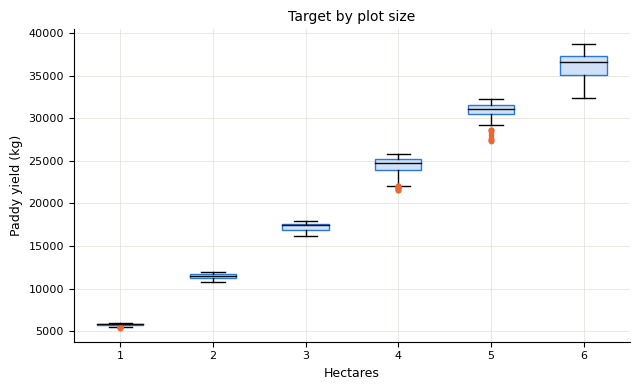

In [12]:
# ---- Continue checking: raw target vs plot size ----
hs = sorted(tr.Hectares.unique())
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.boxplot([tr.loc[tr.Hectares==h, Y] for h in hs], labels=hs, whis=1.5, patch_artist=True, boxprops=dict(facecolor='#cfe0f7', color=BLUE), medianprops=dict(color=INK), flierprops=dict(marker='o', ms=3, mfc=ORANGE, mec=ORANGE))
ax.set(title='Target by plot size', xlabel='Hectares', ylabel='Paddy yield (kg)'); plt.tight_layout(); plt.show()

### 4.2 Reading — grouped by plot size
All 6 boxes climb almost linearly with `Hectares`, and each box lines up with one of the 5 peaks (should be 6 after seeing above image) in the histogram above. The multi-modal shape is explained — yield scales with area, plot size takes only 6 values, so folding 6 size groups into one column produces 6 modes.

**Next check:** if yield scales with area, *yield per hectare* should be fairly constant across plots — a more informative view of the same target.


**Normalise by area**
* `Hectares` is a ratio scale with a true zero, so the ratio `Y2 = Y / Hectares` (yield per hectare) is a meaningful quantity.
* **Assumption:** `Hectares` is never 0 or negative — confirmed in the quality audit above, so the division is always defined.
* `Y2` is a diagnostic view only: never the model target, never a predictor 


,Paddy yield (kg),Yield per hectare (kg/ha)
count,"1,636","1,636"
mean,"22,576.07","5,985.15"
std,"9,257.53",285.8686
min,"5,410","5,410"
25%,"16,389","5,805.5"
50%,"24,620","5,941.5"
75%,"31,035","6,227"
max,"38,814","6,469"
skewness,-0.3046,-0.2257


Yield per hectare relative spread (SD / mean): 4.8%


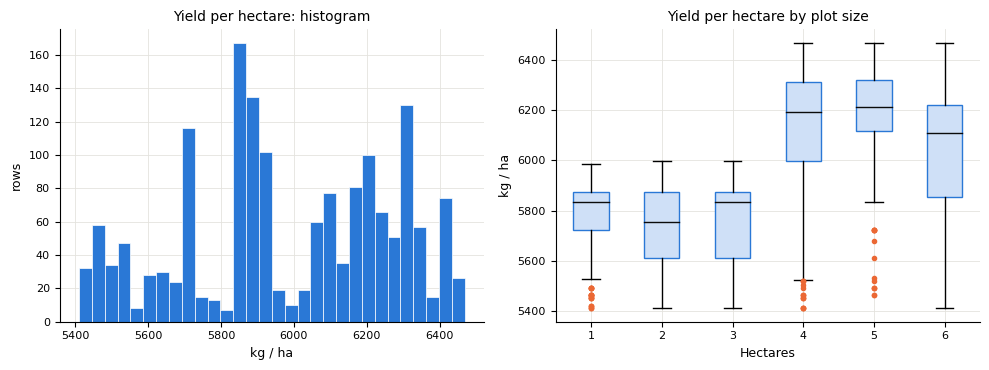

In [13]:
tr['Yield per Ha'] = tr[Y] / tr['Hectares']
Y2 = 'Yield per Ha'
summ2 = pd.DataFrame({'Paddy yield (kg)': tr[Y].describe(), 'Yield per hectare (kg/ha)': tr[Y2].describe()})
summ2.loc['skewness'] = [tr[Y].skew(), tr[Y2].skew()]
display(summ2)
print(f"Yield per hectare relative spread (SD / mean): {tr[Y2].std() / tr[Y2].mean() * 100:.1f}%")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].hist(tr[Y2], bins=30, color=BLUE, edgecolor='white', lw=0.5); ax[0].set(title='Yield per hectare: histogram', xlabel='kg / ha', ylabel='rows')
ax[1].boxplot([tr.loc[tr.Hectares==h, Y2] for h in hs], labels=hs, whis=1.5, patch_artist=True, boxprops=dict(facecolor='#cfe0f7', color=BLUE), medianprops=dict(color=INK), flierprops=dict(marker='o', ms=3, mfc=ORANGE, mec=ORANGE))
ax[1].set(title='Yield per hectare by plot size', xlabel='Hectares', ylabel='kg / ha')
plt.tight_layout(); plt.show()

### 4.3 Reading — yield per hectare
* Yield per hectare is tightly clustered (mean 5,985, SD 286 kg/ha — only **4.8%** relative spread, range 5,410-6,469 kg/ha), and the box-plot by plot size is nearly flat.
* Yield scales almost exactly with area. The puzzle from the raw-target histogram is fully resolved: 6 plot sizes, near-proportional scaling --> 6 modes in the raw target.

**Next check:** flat boxes settle the *level*, but not the *spread*. Whether variance grows with plot size is checked next with numbers, along with balance and transform.


### 4.4 Target balance and transform
**Balance and transform** are the two remaining Guideline checks (transforms considered: log, cube root, Box-Cox). Balance is checked by re-binning the raw target; the transform by comparing skewness *and* the within-plot-size spread of each transform (spread ratio = 1 means constant variance across the 6 plot sizes, i.e. homoscedastic).

In [14]:
# ---- "balance": rows in every value range of the target ----
cnt, edges = np.histogram(yy, bins=10)
bal = pd.DataFrame({'range (kg)': [f'{a:,.0f} - {b:,.0f}' for a, b in zip(edges[:-1], edges[1:])], 'rows': cnt, 'share %': cnt / cnt.sum() * 100})
display(bal.T)
print(f'smallest bin holds {cnt.min()} rows ({cnt.min()/cnt.sum():.1%}); largest {cnt.max()} ({cnt.max()/cnt.sum():.1%}); ratio {cnt.max()/cnt.min():.1f}:1')
print('\nrows per plot size (train):', tr.Hectares.value_counts().sort_index().to_dict())
counts_by_size = tr.Hectares.value_counts().sort_index()
print(f'max/min ratio of rows across plot sizes: {counts_by_size.max()/counts_by_size.min():.1f}:1')
z_target = (yy - yy.mean()) / yy.std(ddof=0)
print(f'max |z| for raw target: {z_target.abs().max():.2f}')
# ---- Check transforms (log, cube root, Box-Cox) and their effect on the *spread* problem ----
def spread_ratio(v):                      # max/min of the within-Hectares standard deviation: 1 = constant variance (homoscedastic)
    s = pd.Series(np.asarray(v)).groupby(tr.Hectares.values).std(); return s.max() / s.min()
bc, lam = stats.boxcox(yy)
trans = {'raw': yy.values, 'log': np.log(yy), 'cube root': np.cbrt(yy), f'Box-Cox (lambda={lam:.2f})': bc}
tt = pd.DataFrame({k: dict(skewness=pd.Series(np.asarray(v)).skew(), spread_ratio_across_plot_sizes=spread_ratio(v)) for k, v in trans.items()}).T
display(tt)

,0,1,2,3,4,5,6,7,8,9
range (kg),"5,410 - 8,750","8,750 - 12,091","12,091 - 15,431","15,431 - 18,772","18,772 - 22,112","22,112 - 25,452","25,452 - 28,793","28,793 - 32,133","32,133 - 35,474","35,474 - 38,814"
rows,145,237,0,277,18,310,57,435,65,92
share %,8.8631,14.4866,0,16.9315,1.1002,18.9487,3.4841,26.5892,3.9731,5.6235


smallest bin holds 0 rows (0.0%); largest 435 (26.6%); ratio inf:1

rows per plot size (train): {1: 145, 2: 237, 3: 277, 4: 371, 5: 467, 6: 139}
max/min ratio of rows across plot sizes: 3.4:1
max |z| for raw target: 1.85


,skewness,spread_ratio_across_plot_sizes
raw,-0.3046,9.6331
log,-1.0534,1.5238
cube root,-0.7746,2.8172
Box-Cox (lambda=1.09),-0.2473,11.4542


**Discussion — target distribution: decisions**

**Balance:**
* The 10-bin histogram has one **empty** bin (12,091-15,431 kg) and bin shares range from 1.1% to 26.6%.
* Two consequences: 
    - (i) the model is only reliable for 1-6 ha
    - (ii) the smallest and largest plots have the fewest training examples.
* **Conclusion: the target is not balanced**, but acceptable — fully explained by data structure (only 6 fixed plot sizes), not sampling error, so no resampling/reweighting is needed.

**Transform:**
* Skew of only -0.30 is within the Guideline's acceptable range. Log (-1.05) and cube root (-0.77) make the skew *worse*; Box-Cox picks λ = 1.09 ≈ 1 (skewness -0.25, practically the raw shape), i.e. "no power transform helps".
* But the last column of the table shows a *different* problem: yield's spread **within each plot size grows with size** — max/min ratio of within-size SD = **9.6 for raw target** vs **1.5 after log**.
* That violates the constant-variance (homoscedasticity) assumption of linear regression — a variance problem, not a skew problem — so if log is used, the justification is **variance stabilisation, not symmetry**.

**Decision:**
* Use raw yield in kg as the model's primary target — it's the actual quantity of interest and UCI's designated target — but also fit a log-target model as a candidate fix for the unequal spread.
* Linear regression does not require a normal *target*; it assumes normally distributed, zero-mean, constant-variance **residuals** — so the target's 6-mode shape is acceptable as long as plot size is in the model.

**Target outliers:** none by the box-plot rule and none by |z|>3 (max |z| ≈ 1.85)

# 5 · Initial feature exploration
**Purpose:** gauge volume and type of data, then drop any column that clearly does **not** affect the target. 

**Tools:** unique-value count, share of the most frequent value, and the **low-variance rule** (drop zero-variance columns; for a Bernoulli/dummy variable, variance = $p(1-p)$, so a category present in over 80% of rows has variance below $0.8\cdot0.2=0.16$).

**Assumption:** a column that (almost) never changes carries no information for *any* model, regardless of target.

**Note on `Trash`:**
* `Trash(in bundles)` was already **dropped as leakage** on domain grounds above — it's not a candidate feature from that point on.
* It's kept in every table/plot below and in the statistical tests further on *on purpose*: if the data independently confirms it has no legitimate signal once plot size is accounted for, that's evidence the domain-based exclusion was correct.
* Wherever `Trash` appears below, read it as **an audit check, not a candidate**.


In [15]:
from sklearn.feature_selection import VarianceThreshold

ov = pd.DataFrame({'dtype': tr.drop(columns=Y2).dtypes.astype(str), 'n_unique': tr.drop(columns=Y2).nunique(),
                   'missing': tr.drop(columns=Y2).isna().sum(),
                   'top value share %': [tr[c].value_counts(normalize=True).iloc[0]*100 for c in tr.drop(columns=Y2).columns]})
ov['role'] = ['target' if c == Y else 'categorical' if c in CAT else 'numeric' for c in ov.index]
display(ov.sort_values(['role', 'n_unique']).head(50))
const = ov[ov.n_unique == 1].index.tolist()
vt = VarianceThreshold(0.0).fit(tr[NUM]); zero_var = [c for c, k in zip(NUM, vt.get_support()) if not k]
print('constant columns (n_unique==1):', const, '| zero-variance numeric (VarianceThreshold(0)):', zero_var)
dom = ov[(ov.role != 'target') & (ov['top value share %'] > 80)]
print('columns whose most frequent value covers > 80 % of rows (variance p(1-p) < 0.16):', dom.index.tolist() if len(dom) else 'none')

,dtype,n_unique,missing,top value share %,role
Soil Types,object,2,0,54.3399,categorical
Nursery,object,2,0,54.9511,categorical
Variety,object,3,0,37.9584,categorical
Wind Direction_D31_D60,object,5,0,37.5917,categorical
Wind Direction_D61_D90,object,5,0,31.9071,categorical
Agriblock,object,6,0,21.3325,categorical
Wind Direction_D1_D30,object,6,0,21.3325,categorical
Wind Direction_D91_D120,object,6,0,21.3325,categorical
30DRain( in mm),float64,3,0,37.4694,numeric
30DAI(in mm),float64,3,0,37.4694,numeric


constant columns (n_unique==1): [] | zero-variance numeric (VarianceThreshold(0)): []
columns whose most frequent value covers > 80 % of rows (variance p(1-p) < 0.16): none


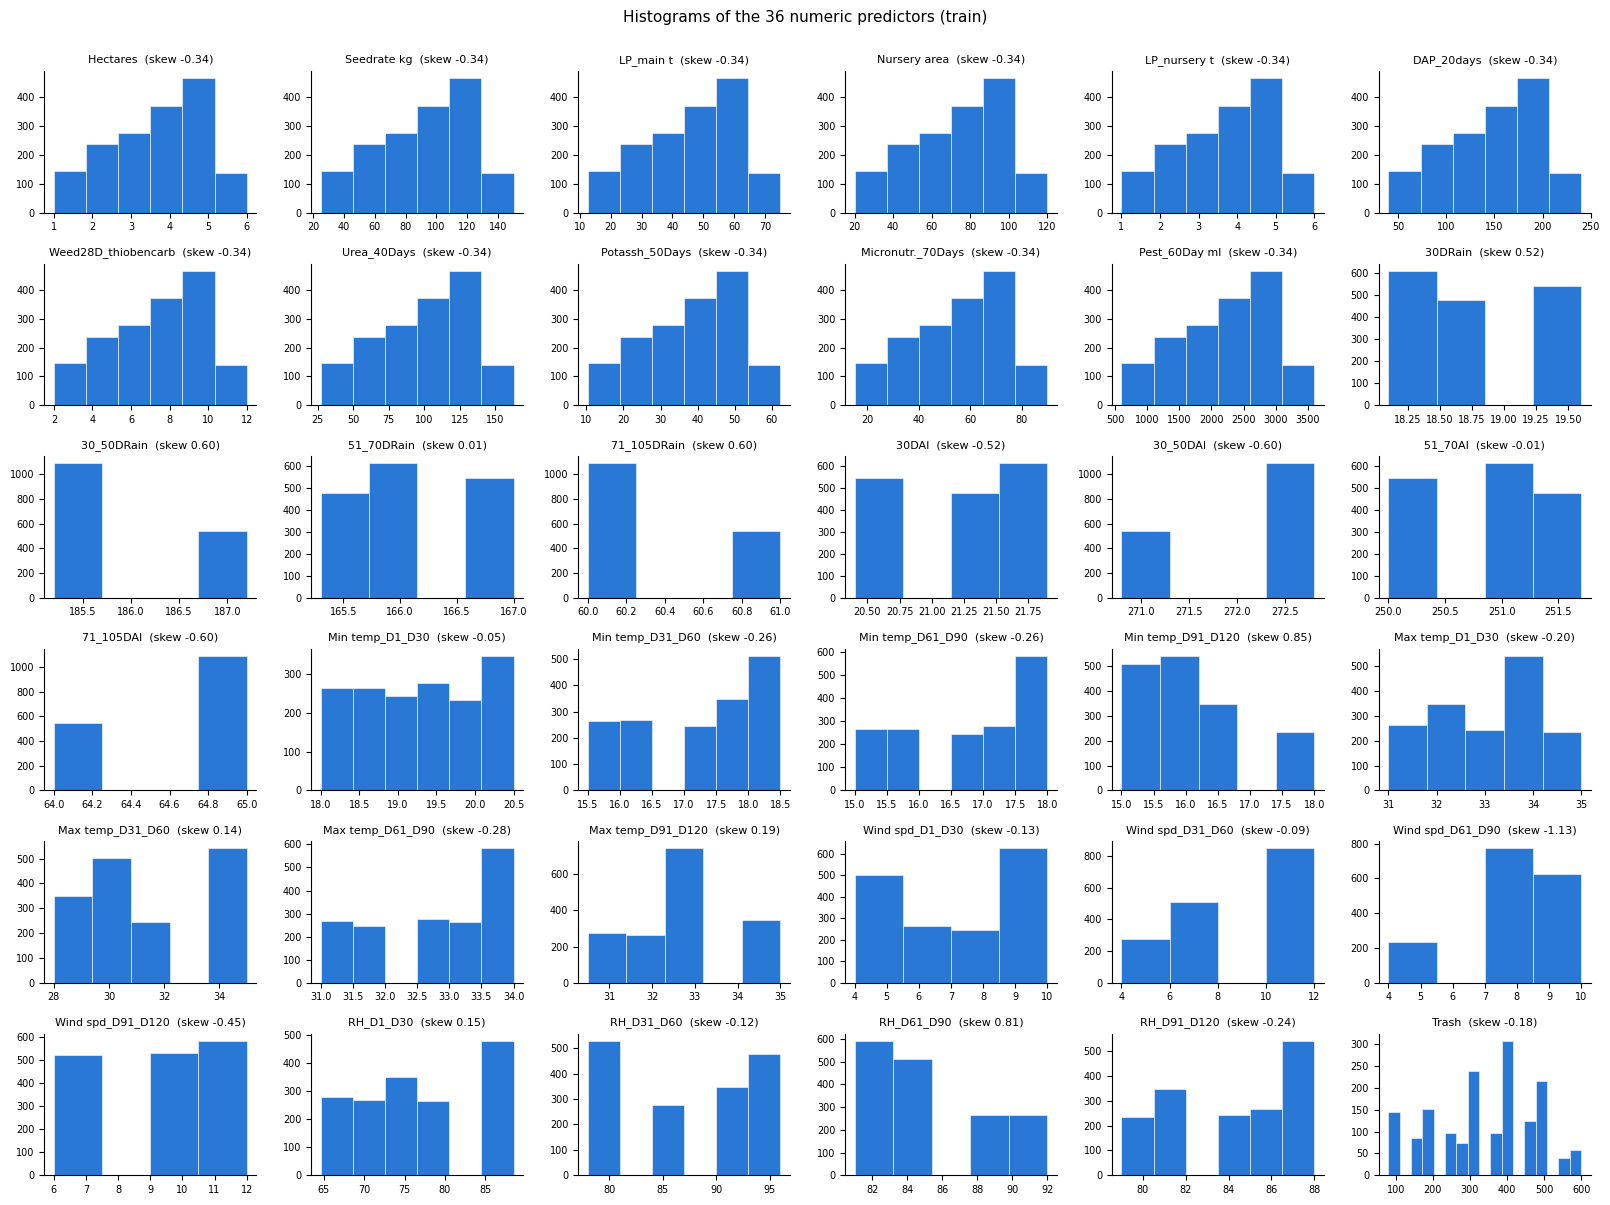

In [16]:
# ---- Visual EDA: histogram for continuous / bar chart for categorical ----
def short(c):
    for a, b in [('Inst Wind Speed', 'Wind spd'), ('Relative Humidity', 'RH'), ('(in Knots)', ''), ('(in Tonnes)', ' t'), ('(in Kg)', ' kg'),
                 ('(in ml)', ' ml'), ('( in mm)', ''), ('(in mm)', ''), ('(in bundles)', ''), ('Wind Direction', 'Wind dir'), ('Micronutrients', 'Micronutr.'),
                 ('LP_nurseryarea', 'LP_nursery'), ('LP_Mainfield', 'LP_main'), ('Nursery area (Cents)', 'Nursery area')]: c = c.replace(a, b)
    return c.strip()

def grid(n, ncols, w, h):
    nr = int(np.ceil(n / ncols)); fig, ax = plt.subplots(nr, ncols, figsize=(ncols*w, nr*h)); ax = np.atleast_1d(ax).ravel()
    for a in ax[n:]: a.axis('off')
    return fig, ax

fig, ax = grid(len(NUM), 6, 2.7, 2.0)
for a, c in zip(ax, NUM):
    a.hist(tr[c], bins=min(25, max(4, tr[c].nunique())), color=BLUE, edgecolor='white', lw=0.4); a.set_title(f'{short(c)}  (skew {tr[c].skew():.2f})', fontsize=8); a.tick_params(labelsize=7); a.grid(False)
plt.suptitle('Histograms of the 36 numeric predictors (train)', y=1.0, fontsize=11); plt.tight_layout(); plt.show()

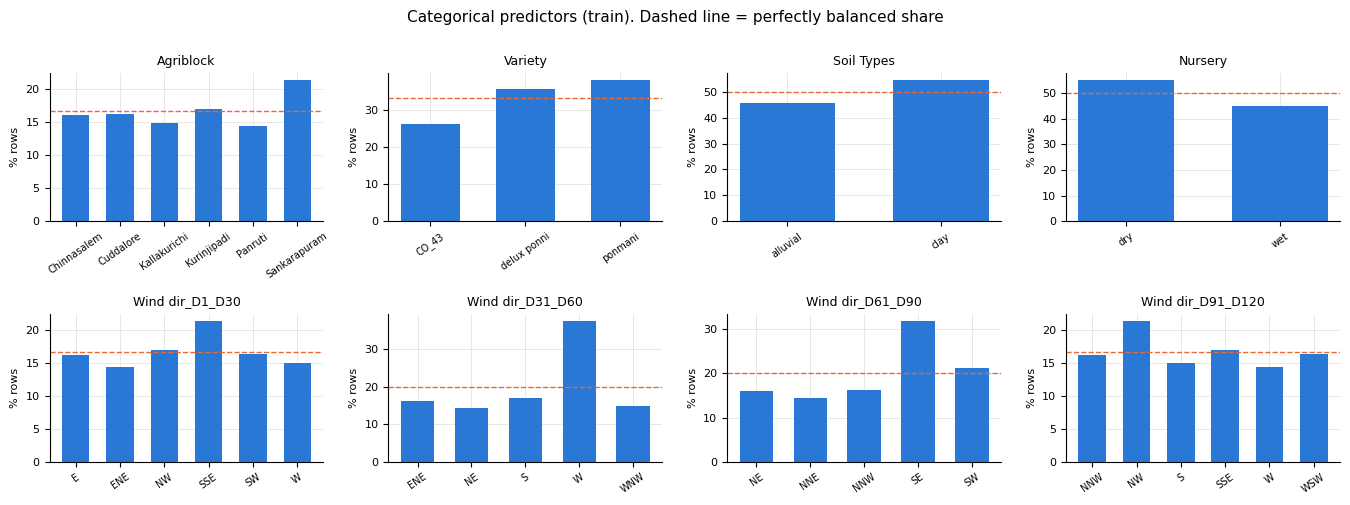

,levels,min_share,max_share
Agriblock,6,14.3643,21.3325
Variety,3,26.3447,37.9584
Soil Types,2,45.6601,54.3399
Nursery,2,45.0489,54.9511
Wind Direction_D1_D30,6,14.3643,21.3325
Wind Direction_D31_D60,5,14.3643,37.5917
Wind Direction_D61_D90,5,14.3643,31.9071
Wind Direction_D91_D120,6,14.3643,21.3325


max (max_share/min_share) ratio, Agriblock/Variety/Soil Types/Nursery: 1.49
|skewness| > 1 : {'Inst Wind Speed_D61_D90(in Knots)': -1.13}
|skewness| > 0.5: 9 of 36 numeric features


In [17]:
fig, ax = grid(len(CAT), 4, 3.4, 2.5)
for a, c in zip(ax, CAT):
    vc = tr[c].value_counts(normalize=True).sort_index() * 100
    a.bar(vc.index, vc.values, color=BLUE, width=0.62); a.set_title(short(c), fontsize=9); a.set_ylabel('% rows', fontsize=8); a.tick_params(axis='x', rotation=35, labelsize=7); a.axhline(100/len(vc), color=ORANGE, lw=1, ls='--')
plt.suptitle('Categorical predictors (train). Dashed line = perfectly balanced share', y=1.0, fontsize=11); plt.tight_layout(); plt.show()
bal = pd.DataFrame({c: dict(levels=tr[c].nunique(), min_share=tr[c].value_counts(normalize=True).min()*100, max_share=tr[c].value_counts(normalize=True).max()*100) for c in CAT}).T
display(bal)
print('max (max_share/min_share) ratio, Agriblock/Variety/Soil Types/Nursery:', round((bal.loc[['Agriblock','Variety','Soil Types','Nursery']].max_share / bal.loc[['Agriblock','Variety','Soil Types','Nursery']].min_share).max(), 2))
sk = tr[NUM].skew().sort_values(); print('|skewness| > 1 :', sk[sk.abs() > 1].round(2).to_dict()); print('|skewness| > 0.5:', len(sk[sk.abs() > 0.5]), 'of', len(sk), 'numeric features')

### 5.1 Discussion — feature exploration
**Volume and type:**
* 1,636 training rows, **44 non-target columns** (36 numeric, 8 categorical) — but only **43 real candidates**; `Trash` was already dropped as leakage above and appears below only for the audit reasoning above.
* No missing values.

**Column dropping:**
* No column is constant (`VarianceThreshold(0)` drops nothing), and no column has one value covering over 80% of rows (highest dominant share: 54.9%, `Nursery`). So **no column is dropped by the low-variance rule**.
* By domain knowledge, no column is an identifier, so none is dropped as clearly unrelated to the target.

**What the histograms show (statistics + plots)**
* Almost every numeric column takes only **3-6 distinct values** (`Trash` has 17 — shown for audit only, already excluded), so histograms are a few bars, not smooth curves — the data behaves like a handful of scenarios.
* **11 columns — `Hectares` plus 10 input columns — have identical histograms and identical skewness (-0.34)**. They look like the same variable on different scales.
* The 4 rain columns and 4 AI columns are **mirror images** of each other (skewness +0.52 vs -0.52, +0.60 vs -0.60, +0.01 vs -0.01).
* Skewness: only `Wind spd_D61_D90` has |skew| > 1 (-1.13); 9 of 36 features have |skew| > 0.5. Decision: **don't transform predictors** — skew is mild, columns have too few levels for log/Box-Cox to meaningfully reshape them, and linear regression doesn't require normal predictors (the assumption is on residuals).

**Categorical balance:**
* From the bar charts above (dashed line = perfectly equal share), every column's bars sit near the dashed line — no category stands out.
* Min-max shares: Agriblock 14.4-21.3%, Variety 26.3-38.0%, Soil 45.7-54.3%, Nursery 45.0-55.0% — under 1.5x apart at most, balanced enough here; no resampling or class-weighting needed.
* `Wind Direction_D1_D30` and `_D91_D120` have exactly the same share pattern as `Agriblock` (max 21.3%, min 14.4%) — a clue that wind direction depends on the agri-block (location); checked later.

# 6 · Outlier analysis
**Why it matters:** least squares minimises *squared* residuals, so a single extreme point can pull the fitted line and create or hide correlations. Causes: data-entry errors, sensor faults, or genuinely rare events.
**Detection tools used and their assumptions**

| Tool | Rule | Assumption / weakness |
|---|---|---|
| Visual (histogram / box / scatter) | look for isolated points | judgement-based |
| **z-score** (2-3 SD from mean) | \|z\| > 3 | data must be roughly **Gaussian**; mean and SD themselves get pulled up by outliers ("masking") |
| **Outlier Removal Algorithm** (fit on all data --> find largest ~10% residuals --> remove --> refit, iterate) | large residual relative to model expectation | too many rounds removes good rows too; needs a reasonably good starting model |

features/targets with at least one |z|>3 flag:


,z_gt_3,n_unique


z>3 flags in total: 0  (over 38 columns x 1636 rows)


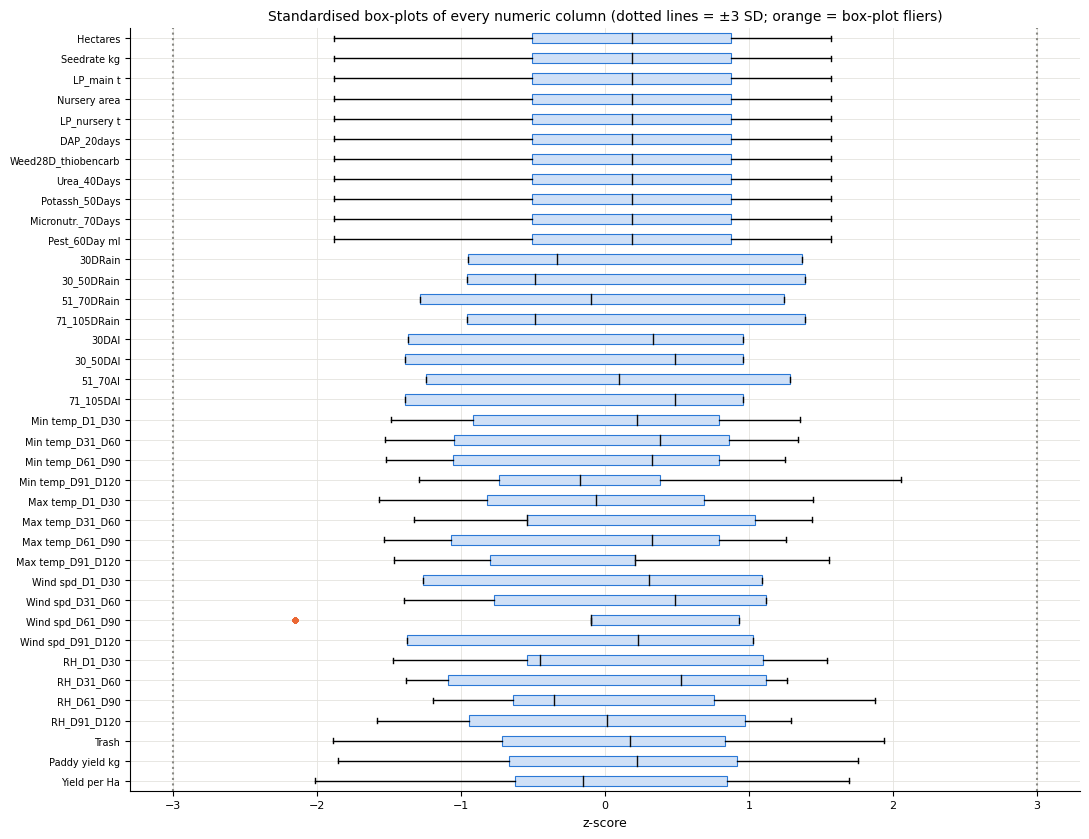

In [18]:
def flags(s):
    z = (s - s.mean()) / s.std(ddof=0)
    return dict(z_gt_3=int((z.abs() > 3).sum()), n_unique=s.nunique())
out = pd.DataFrame({c: flags(tr[c]) for c in NUM + [Y, Y2]}).T

print('features/targets with at least one |z|>3 flag:'); display(out[out.z_gt_3 > 0])
print(f'z>3 flags in total: {int(out.z_gt_3.sum())}  (over {len(out)} columns x {len(tr)} rows)')

fig, ax = plt.subplots(figsize=(11, 8.5)); cols = NUM + [Y, Y2]
Z = [(tr[c] - tr[c].mean()) / tr[c].std(ddof=0) for c in cols]
ax.boxplot(Z, vert=False, patch_artist=True, boxprops=dict(facecolor='#cfe0f7', color=BLUE, lw=0.8), medianprops=dict(color=INK), flierprops=dict(marker='o', ms=3, mfc=ORANGE, mec=ORANGE))
ax.set_yticklabels([short(c) for c in cols], fontsize=7); ax.axvline(-3, color=GREY, ls=':'); ax.axvline(3, color=GREY, ls=':'); ax.invert_yaxis()
ax.set(title='Standardised box-plots of every numeric column (dotted lines = ±3 SD; orange = box-plot fliers)', xlabel='z-score'); plt.tight_layout(); plt.show()

### 6.1 Discussion — outliers
**Statistics (z-score):** across 38 columns (36 predictors + 2 targets) and 1,636 rows, **not a single value is flagged with |z| > 3**.

**Plots (box-plot):**
* In the standardised box-plots every whisker sits comfortably within ±3 SD.
* One orange point appears in `Wind spd_D61_D90`: it's just the "4 knots" level (one of 3 levels: 4/8/10). With only 3 levels and 47% of rows at one value, the quartiles compress tightly enough to make the lowest level look like it's outside the box — a false alarm from applying a box-plot to a discrete column, not a data error.
* Target and yield-per-hectare have no flagged points in either view.

**Decision: no rows removed, no values capped.** 

Reasons:
1. No evidence of a measurement error — every extreme value is a physically plausible yield for that plot size (see the by-plot-size box-plot above).
2. Removing genuinely large plots would shrink real variance and bias the slope.


# 7 · Missing-value analysis
Guideline rule: handle each column separately; **missing > 30% --> drop the column**; a few missing rows --> drop those rows; otherwise **impute** (mean/median/mode/regression/nearest-neighbour hot-deck) .

In [19]:
miss = pd.DataFrame({'missing_n': tr.isna().sum(), 'missing_%': tr.isna().mean() * 100})
print('columns with any missing value:', int((miss.missing_n > 0).sum()), '| maximum missing % in any column:', miss['missing_%'].max())
print('missing-value check on the TEST part (only counts, nothing learned from it):', int(test.isna().sum().sum()))

columns with any missing value: 0 | maximum missing % in any column: 0.0
missing-value check on the TEST part (only counts, nothing learned from it): 0


**Result: nothing is missing.** No rows or columns were dropped. Still, The table below gives the decision rule and its assumption.

| Situation | Action | Reason / assumption |
|---|---|---|
| column missing > 30% | drop the column | too little data left to impute reliably (Guideline) |
| only a few rows missing (< ~5%) | drop those rows | little data lost; no bias if the rows are missing at random |
| skewed / outlier-prone numeric | **median** | robust to extremes |
| roughly symmetric numeric | **mean** | keeps the average, but shrinks variance and weakens correlation |
| categorical | **mode** | most likely category, but biases toward the majority group |
| missingness is explained by *other columns* that are predictive | **regression / kNN (hot-deck)** imputation | exploits real relationships; only works if they exist |


### 7.1 Discussion — missing values
* **Reality:** 0 missing cells across all 45 training columns (and 0 in test), so no column was dropped (Guideline: >30%) and no row was dropped or imputed.
* **Decision:** nothing to treat, so the preprocessing pipeline has no imputation step. If future data had missing values, the table above would be applied, fitting any imputer on train only.


# 8 · Feature selection — continuous features
**Goal:** keep columns related to the target, using only **filter methods**. Everything is computed on `train` only.

* Three targets are considered: raw yield `Y`; yield per hectare `Y/ha`; and **size-adjusted `Y/ha`** (= `Y/ha` minus the train mean `Y/ha` for that plot size).
* Plot size dominates `Y` and can mask everything else — a non-significant test isn't proof of no relationship when nuisance variance is this large; the adjusted target removes that nuisance and can reveal weaker effects.
* `Trash` (already dropped as leakage above) is included in the tests below on purpose too, for the same audit reason as before: to check its apparent correlation empirically, not because it's a candidate.

### 8.1 Visual analysis — scatter plots
Each panel: feature (x) vs target (y), blue = rows, **orange line = the target's mean at each observed x value** (shows the relationship's shape even with few unique x values), `r` = Pearson correlation.


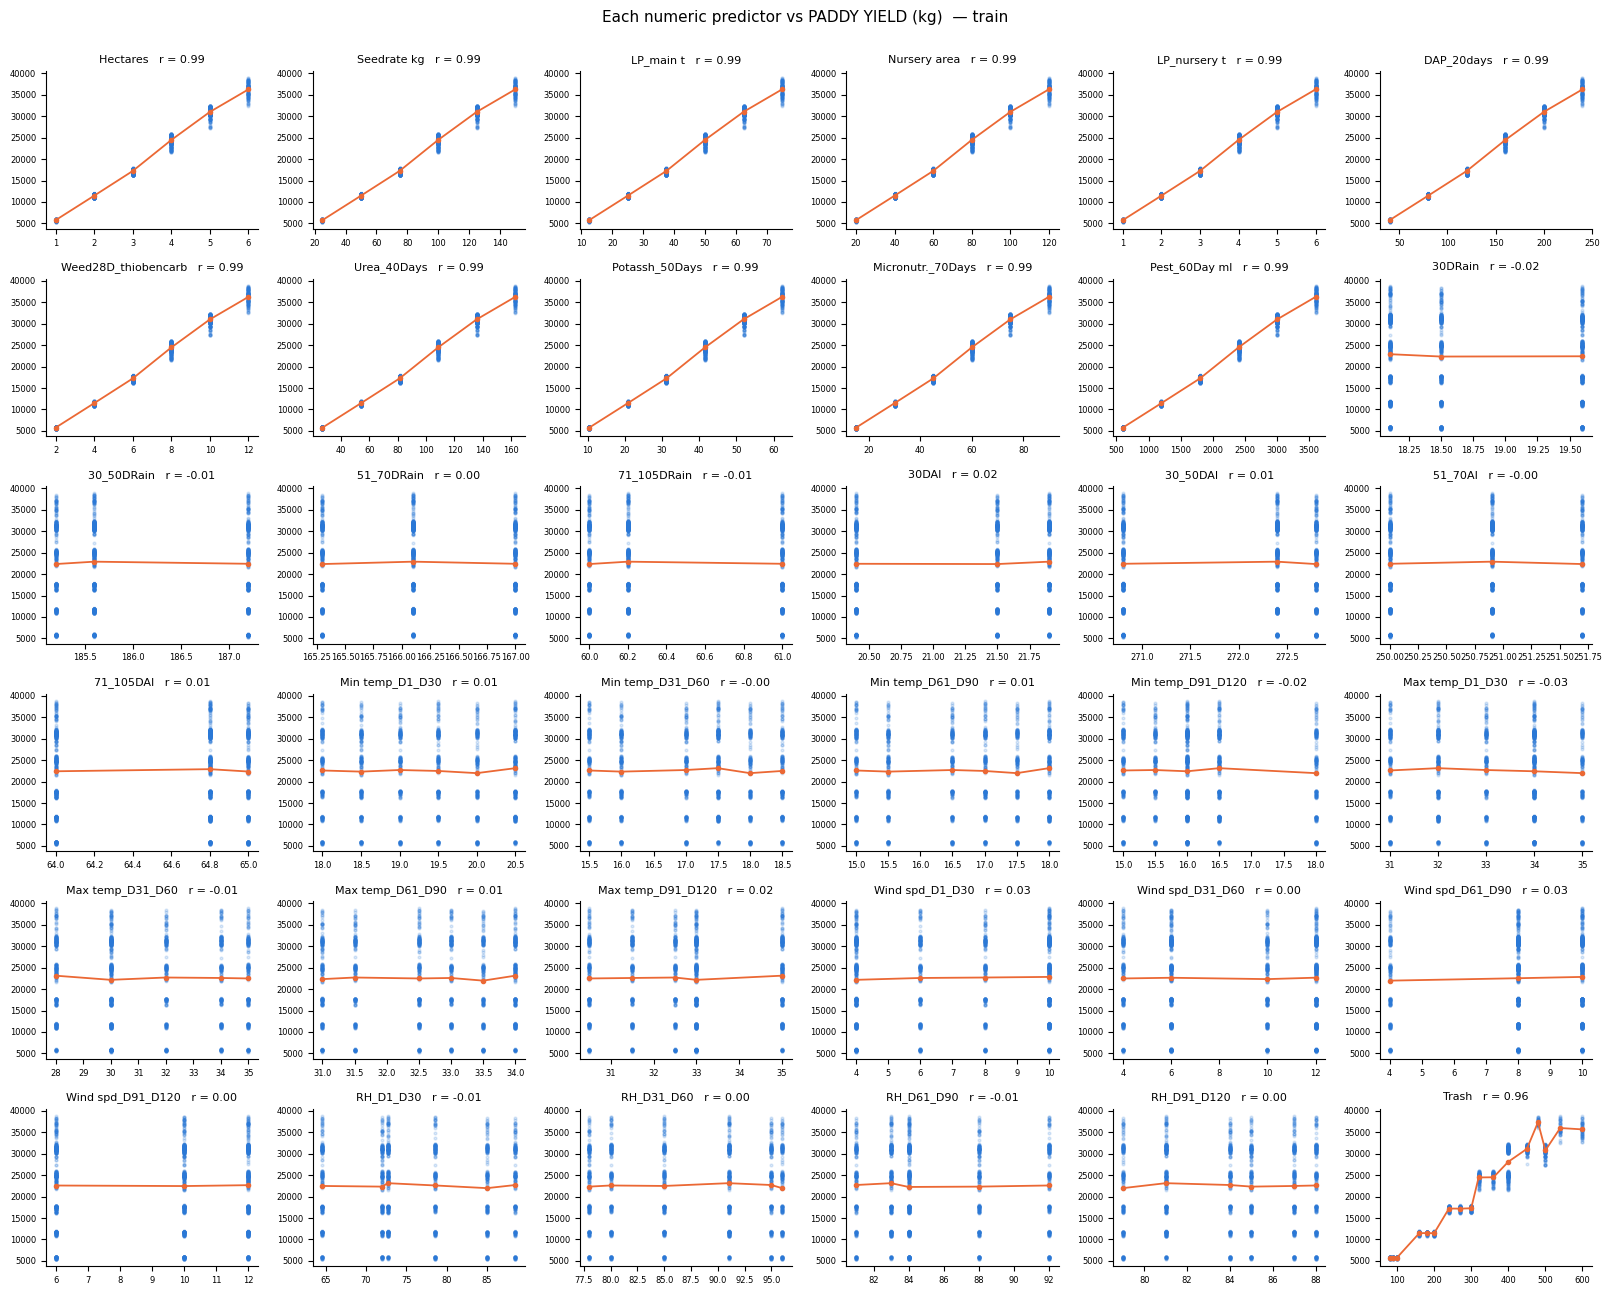

In [20]:
def scatter_grid(target, ttl):
    fig, ax = grid(len(NUM), 6, 2.7, 2.15)
    for a, c in zip(ax, NUM):
        x, yv = tr[c].values, tr[target].values
        a.scatter(x, yv, s=4, alpha=.16, color=BLUE, rasterized=True)
        m = tr.groupby(c)[target].mean(); a.plot(m.index, m.values, '-o', color=ORANGE, ms=3, lw=1.3)
        a.set_title(f'{short(c)}   r = {np.corrcoef(x, yv)[0,1]:.2f}', fontsize=8); a.tick_params(labelsize=6); a.grid(False)
    plt.suptitle(ttl, y=1.0, fontsize=11); plt.tight_layout(); plt.show()
scatter_grid(Y, 'Each numeric predictor vs PADDY YIELD (kg)  — train')

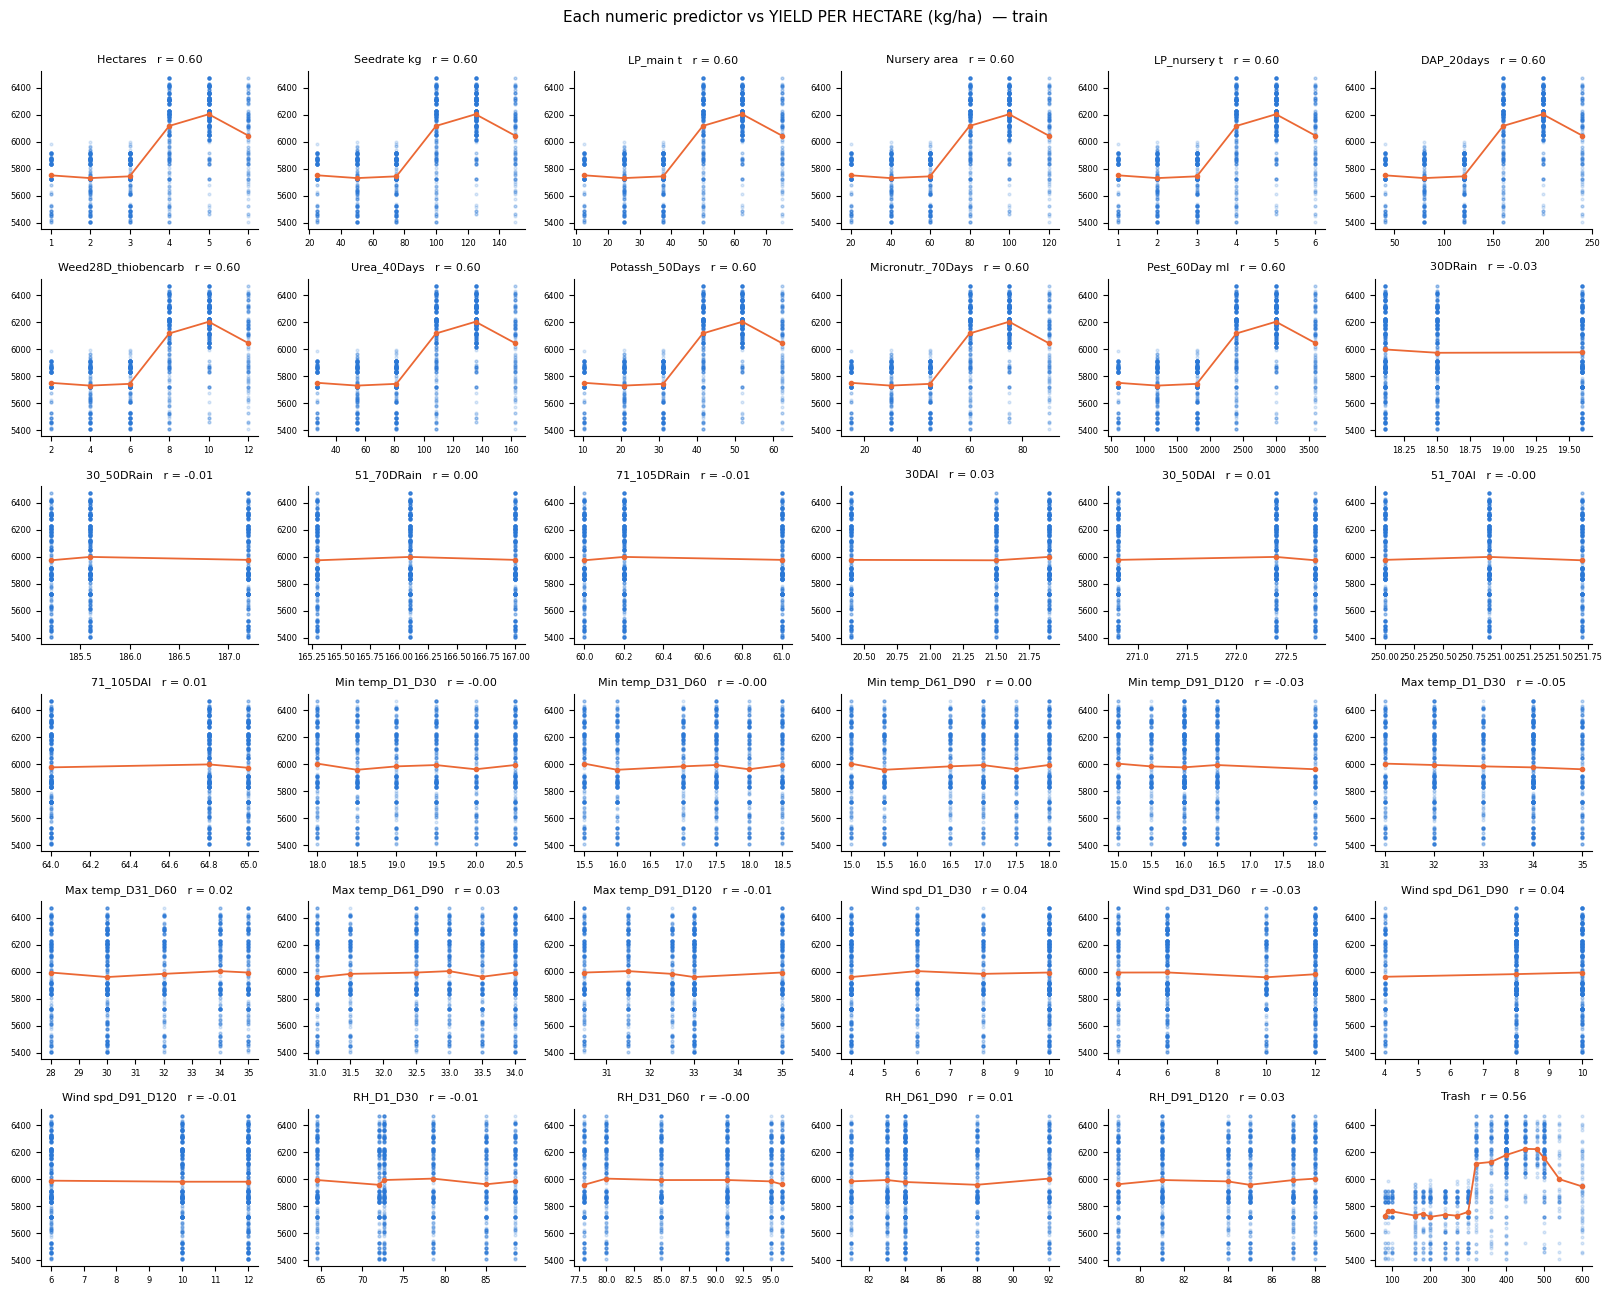

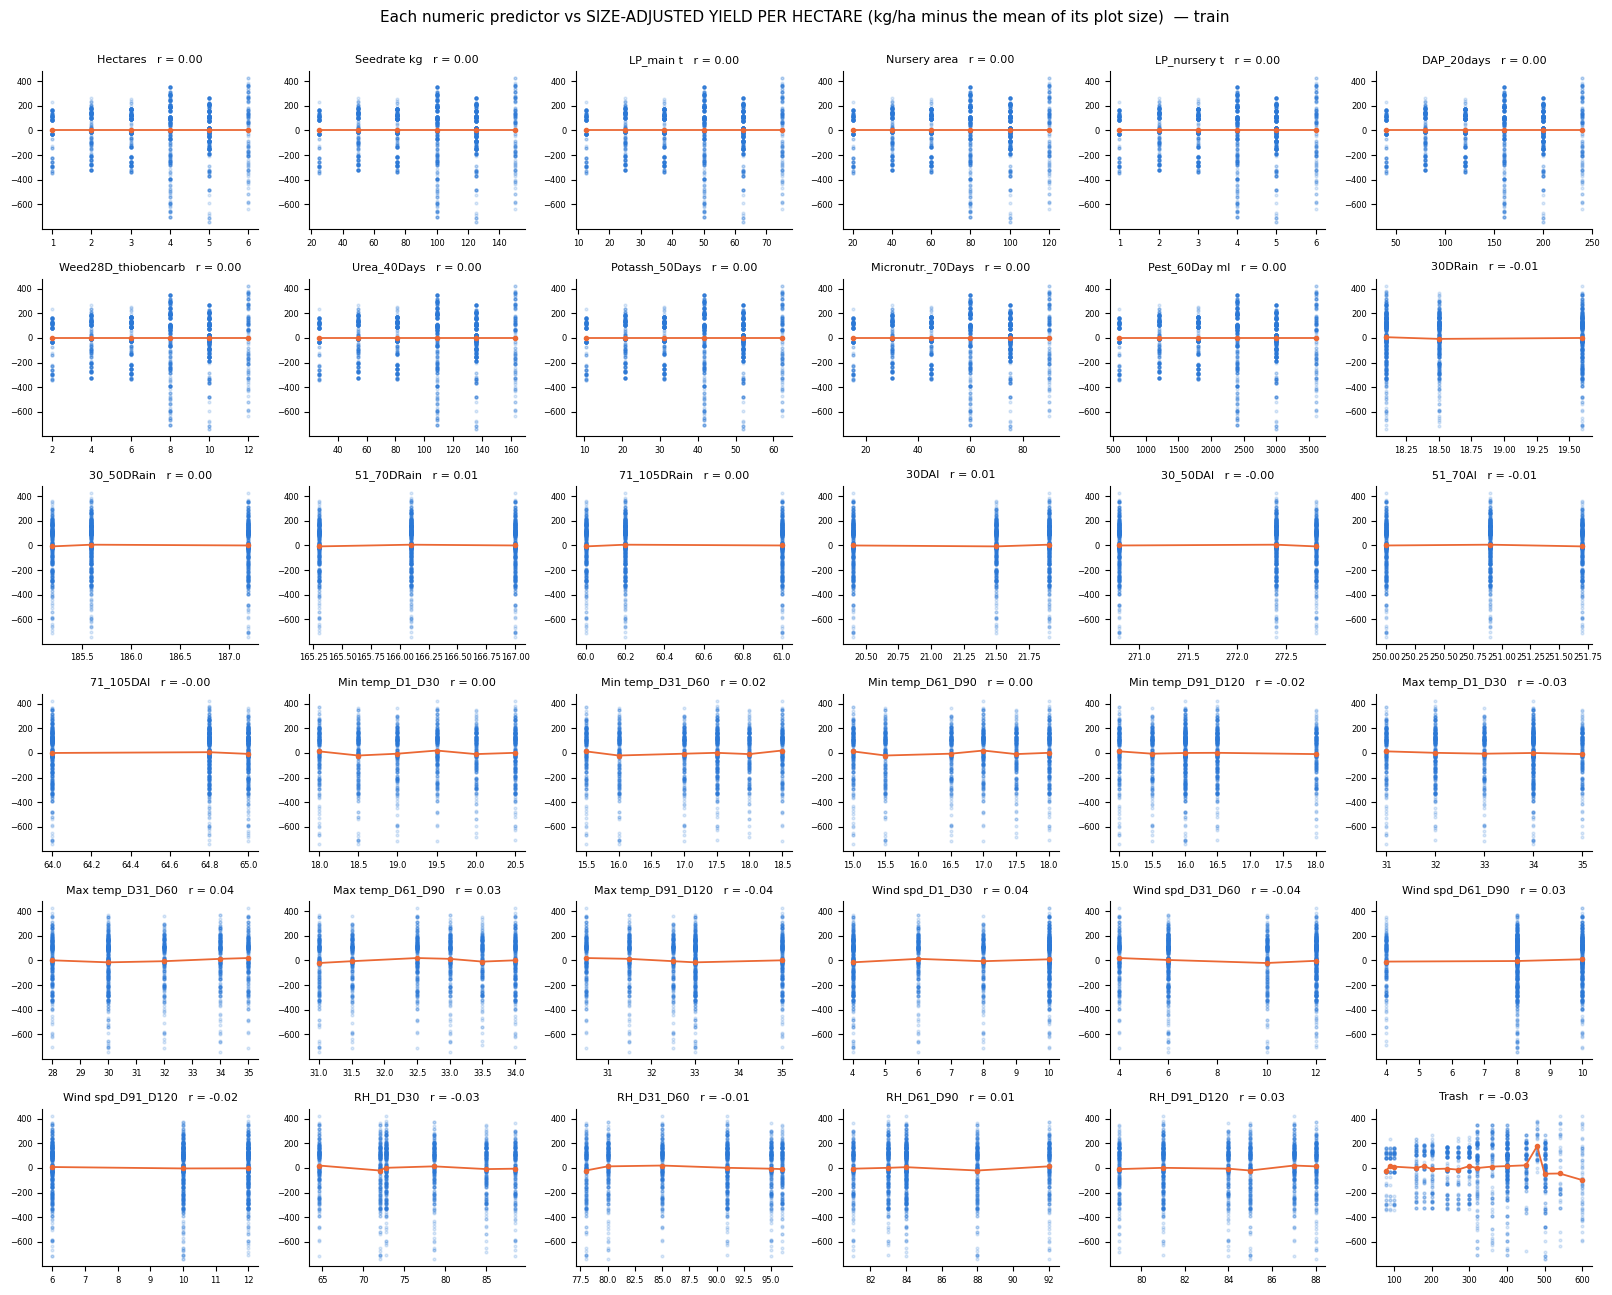

In [21]:
# size-adjusted yield/ha: subtract the TRAIN mean yield/ha for the same plot size (removes the plot-size "nuisance" effect described above)
size_mean = tr.groupby('Hectares')[Y2].mean()
tr['Yha adj'] = tr[Y2] - tr['Hectares'].map(size_mean)
Y3 = 'Yha adj'
scatter_grid(Y2, 'Each numeric predictor vs YIELD PER HECTARE (kg/ha)  — train')
scatter_grid(Y3, 'Each numeric predictor vs SIZE-ADJUSTED YIELD PER HECTARE (kg/ha minus the mean of its plot size)  — train')

**Reading the plots**
* **Size/input columns** (`Hectares` and the 10 input columns): identical panels. Against raw yield all lie on one straight line (r = 0.99). Against yield/ha (r = 0.60) the mean rises from 1-3 ha to 4-5 ha and drops at 6 ha, so it is not a straight line. Against size-adjusted yield/ha the mean is flat at 0, since the plot-size level has been removed.
* **Weather columns** (rain, AI, temperature, wind speed, humidity): each has only 2-6 distinct values, and the orange mean line is flat against all three targets (|r| ≤ 0.05). No visible trend.
* **`Trash`:** follows plot size against raw yield (r = 0.96) and yield/ha (r = 0.56), but is flat against the size-adjusted target (r = -0.03).
* **Interpretation:** only plot size shows a visible relationship with yield.

### 8.2 Statistical analysis
| Tool | Measures | Assumptions / limits |
|---|---|---|
| **Correlation r** with the **F-test** p-value (`f_regression`; H0: no linear relationship) | strength and sign of the *linear* relationship | relationship is linear, no influential outlier, rows independent; significant if p < 0.05 |
| **Mutual information** (nats) | *any* kind of dependency, ≥ 0, no p-value | the course uses MI as a **ranking**, not a thresholded test; all columns are treated as discrete (≤ 17 levels) |

**Rule:** a feature is a candidate if its F-test p < 0.05 for at least one of the three targets; MI is used to rank features and to see dependencies the linear correlation cannot.

In [22]:
from sklearn.feature_selection import f_regression, mutual_info_regression

Xn = tr[NUM].values
def mi_all(y): return mutual_info_regression(Xn, y, discrete_features=True, random_state=SEED)
ct_tab = pd.DataFrame(index=NUM)
for tag, t in [('Y', Y), ('Yha', Y2), ('adj', Y3)]:
    ct_tab['r_' + tag] = [np.corrcoef(tr[c], tr[t])[0, 1] for c in NUM]
    ct_tab['p_' + tag] = f_regression(Xn, tr[t].values)[1]
for tag, t in [('Y', Y), ('Yha', Y2), ('adj', Y3)]:
    ct_tab['MI_' + tag] = mi_all(tr[t].values)
ct_tab = ct_tab.reindex(ct_tab.r_Y.abs().sort_values(ascending=False).index)
display(ct_tab)

,r_Y,p_Y,r_Yha,p_Yha,r_adj,p_adj,MI_Y,MI_Yha,MI_adj
Potassh_50Days,0.9946,0,0.601,3.18e-161,2.39e-16,1,1.6994,0.4334,1.2695
Seedrate(in Kg),0.9946,0,0.601,3.18e-161,2.24e-16,1,1.6994,0.4334,1.2695
LP_Mainfield(in Tonnes),0.9946,0,0.601,3.18e-161,2.24e-16,1,1.6994,0.4334,1.2695
Pest_60Day(in ml),0.9946,0,0.601,3.18e-161,2.45e-16,1,1.6994,0.4334,1.2695
Micronutrients_70Days,0.9946,0,0.601,3.18e-161,2.20e-16,1,1.6994,0.4334,1.2695
Nursery area (Cents),0.9946,0,0.601,3.18e-161,2.92e-16,1,1.6994,0.4334,1.2695
DAP_20days,0.9946,0,0.601,3.18e-161,2.92e-16,1,1.6994,0.4334,1.2695
Urea_40Days,0.9946,0,0.601,3.18e-161,2.21e-16,1,1.6994,0.4334,1.2695
Hectares,0.9946,0,0.601,3.18e-161,2.16e-16,1,1.6994,0.4334,1.2695
LP_nurseryarea(in Tonnes),0.9946,0,0.601,3.18e-161,2.16e-16,1,1.6994,0.4334,1.2695


In [23]:
# ---- Audit the `Trash` leakage suspect: information beyond plot size ----
print(f"corr(Trash, yield)                                   = {tr[TRASH].corr(tr[Y]):.3f}")
print(f"corr(Trash, Hectares)                                = {tr[TRASH].corr(tr['Hectares']):.3f}")
print(f"corr(Trash, yield per ha)                            = {tr[TRASH].corr(tr[Y2]):.3f}")
print(f"corr(Trash, size-adjusted yield per ha)              = {tr[TRASH].corr(tr[Y3]):.3f}  (p = {f_regression(tr[[TRASH]], tr[Y3])[1][0]:.2f})")
print('corr(Trash, yield per ha) inside each plot size:', {int(k): round(v, 2) for k, v in tr.groupby('Hectares').apply(lambda g: g[TRASH].corr(g[Y2])).items()})
print('Trash per hectare takes the values', sorted((tr[TRASH] / tr.Hectares).unique()))

corr(Trash, yield)                                   = 0.958
corr(Trash, Hectares)                                = 0.968
corr(Trash, yield per ha)                            = 0.556
corr(Trash, size-adjusted yield per ha)              = -0.033  (p = 0.19)
corr(Trash, yield per ha) inside each plot size: {1: 0.09, 2: -0.03, 3: 0.05, 4: -0.01, 5: -0.2, 6: -0.44}
Trash per hectare takes the values [80.0, 90.0, 100.0]


In [24]:
# ---- 8.3 continuous feature summary (statistics only) ----
def family(c):
    return ('size & inputs' if c == 'Hectares' or c in INPUTS else 'rain' if c in RAIN else 'AI' if c in AI else 'min temp' if c in TMIN else 'max temp' if c in TMAX
            else 'wind speed' if c in WIND else 'humidity' if c in RH else 'Trash')

summ = pd.DataFrame({'family': {c: family(c) for c in NUM}})
for k in ['r_Y', 'p_Y', 'r_Yha', 'p_Yha', 'r_adj', 'p_adj']: summ[k] = ct_tab[k]
display(summ.sort_values('family'))

g = summ.assign(**{f'abs_{k}': summ[k].abs() for k in ('r_Y', 'r_Yha', 'r_adj')}, MI_Y=ct_tab.MI_Y, MI_Yha=ct_tab.MI_Yha, MI_adj=ct_tab.MI_adj).groupby('family')
display(pd.DataFrame({'n': g.size(), 'max |r_Y|': g.abs_r_Y.max(), 'max |r_Yha|': g.abs_r_Yha.max(), 'max |r_adj|': g.abs_r_adj.max(),
                      'min p_Y': g.p_Y.min(), 'min p_Yha': g.p_Yha.min(), 'min p_adj': g.p_adj.min(),
                      'max MI_Y': g.MI_Y.max(), 'max MI_Yha': g.MI_Yha.max(), 'max MI_adj': g.MI_adj.max()}))
print('features with p < 0.05 for at least one target:', sorted(short(c) for c in NUM if min(ct_tab.loc[c, ['p_Y', 'p_Yha', 'p_adj']]) < 0.05))

,family,r_Y,p_Y,r_Yha,p_Yha,r_adj,p_adj
30DAI(in mm),AI,0.0184,0.4565,0.0263,0.2873,0.0077,0.756
30_50DAI(in mm),AI,0.0078,0.7515,0.0109,0.66,-0.0047,0.8482
51_70AI(in mm),AI,-0.0006,0.9801,-0.0014,0.9556,-0.013,0.5989
71_105DAI(in mm),AI,0.0078,0.7515,0.0109,0.66,-0.0047,0.8482
Trash(in bundles),Trash,0.9582,0,0.5558,2.83e-133,-0.0325,0.1886
Relative Humidity_D91_D120,humidity,5.12e-05,0.9983,0.0257,0.298,0.0336,0.1738
Relative Humidity_D61_D90,humidity,-0.0093,0.7063,0.0076,0.7578,0.0079,0.7483
Relative Humidity_D31_D60,humidity,0.0035,0.8879,-0.0043,0.8611,-0.0068,0.7825
Relative Humidity_D1_D30,humidity,-0.008,0.7478,-0.0127,0.6083,-0.0272,0.271
Max temp_D91_D120,max temp,0.019,0.4415,-0.0114,0.6458,-0.0355,0.1508


,n,max |r_Y|,max |r_Yha|,max |r_adj|,min p_Y,min p_Yha,min p_adj,max MI_Y,max MI_Yha,max MI_adj
family,,,,,,,,,,
AI,4,0.0184,0.0263,0.013,0.4565,0.2873,0.5989,0.0035,0,0
Trash,1,0.9582,0.5558,0.0325,0,2.83e-133,0.1886,1.5785,0.44,0.9009
humidity,4,0.0093,0.0257,0.0336,0.7063,0.298,0.1738,0.0095,0.0068,0.0102
max temp,4,0.0288,0.0457,0.045,0.2437,0.0644,0.0688,0.0025,0,0.0103
min temp,4,0.0152,0.0327,0.0235,0.5383,0.186,0.3413,0.0025,0,0.0103
rain,4,0.0184,0.0263,0.013,0.4565,0.2873,0.5989,0.0035,0,0
size & inputs,11,0.9946,0.601,2.92e-16,0,3.18e-161,1,1.6994,0.4334,1.2695
wind speed,4,0.0307,0.041,0.043,0.2153,0.0976,0.082,0.0046,0,0.0173


features with p < 0.05 for at least one target: ['DAP_20days', 'Hectares', 'LP_main t', 'LP_nursery t', 'Micronutr._70Days', 'Nursery area', 'Pest_60Day ml', 'Potassh_50Days', 'Seedrate kg', 'Trash', 'Urea_40Days', 'Weed28D_thiobencarb']


### 8.3 Discussion — continuous feature selection
**Rule:** keep a feature if the F-test p < 0.05 for at least one of the three targets; MI is used as a ranking. The printed list of features with p < 0.05 contains exactly the 11 size/input columns and `Trash`.

**Two very different groups of features emerge.**

**(a) `Hectares` plus 10 input columns** (`Seedrate`, `LP_Mainfield`, `Nursery area`, `LP_nurseryarea`, `DAP_20days`, `Weed28D_thiobencarb`, `Urea_40Days`, `Potassh_50Days`, `Micronutrients_70Days`, `Pest_60Day`):
* All 11 have **r = 0.9946 with raw yield** (p reported as 0, below floating-point resolution) and **r = 0.601 with yield/ha** (p = 3.18e-161) — identical to 4 decimal places because each input is an exact multiple of `Hectares`.
* Against the **size-adjusted** target, all 11 have |r| ≤ 3e-16 (numerically zero, p = 1): once plot-size level is removed, there's nothing left to correlate with — exactly what "exact multiple of Hectares" predicts.
* **Decision:** all 11 pass the rule (p far below 0.05) --> **keep as candidates**.

**(b) 24 weather columns + `Trash`:**
* Every weather correlation with every target is tiny (max |r| = 0.0457 across rain, AI, min/max temperature, wind speed and humidity) and **none is significant** (smallest p = 0.064, `Max temp_D1_D30` vs yield/ha). Their MI is also near zero (max 0.0173 nats, against 1.27 for the size/input group).
* **Decision:** all 24 weather columns fail the rule --> **reject**.
* `Trash` looks like a superb predictor of raw yield (r = 0.958) — but it correlates 0.968 with `Hectares`, and against the **size-adjusted** target it's **r = -0.033, p = 0.19** — not significant.
* Inside each plot size, its correlation with yield/ha is near zero for 1-4 ha (|r| ≤ 0.09) and *negative* for 5 ha (-0.20) and 6 ha (-0.44) — never a positive relationship beyond plot size. Trash per hectare takes only the values 80, 90 and 100.
* This *empirically* supports the leakage decision above: `Trash`'s apparent power is a stand-in for plot size, not new information.
* **Decision:** `Trash` --> **reject** (leakage: a harvest by-product, so it is not available at prediction time).

**A detail with a lesson about mutual information:**
* Both `Trash` and the size/input group have **large MI against the size-adjusted target, despite correlation ≈ 0** (MI_adj = 0.90 nats for `Trash` and 1.27 for the size/input group, against at most 0.0173 for any weather column).
* Not a contradiction: correlation and the F-test only see a *linear shift in the mean*; MI also sees other dependencies, such as **changes in spread**. The target analysis already showed the spread of yield grows with plot size — MI is picking up exactly that, something linear-regression coefficients can't use to predict the mean. This matches  point that *"the F-test captures only linear dependency… mutual information can capture any kind of dependency."*
* **Effect on decisions:** it does **not** change which feature to keep for point prediction (a dependency that is only in the spread can't be exploited by the mean), but it's a second reason `Hectares` matters — for the residual-spread structure, not just the mean (used again when choosing between raw and log-yield models).

**Conclusion:** there is **only one continuous group with signal — plot size**, currently represented by 11 perfectly collinear columns; the redundancy analysis reduces it to `Hectares` alone. **No weather column and no `Trash`** is kept in the final model.

# 9 · Feature selection — categorical features
### 9.1 Visual analysis — target box-plots by category
Boxes at different heights mean the category matters; identical boxes mean it doesn't. Three views: raw yield, yield per hectare, and size-adjusted yield per hectare.

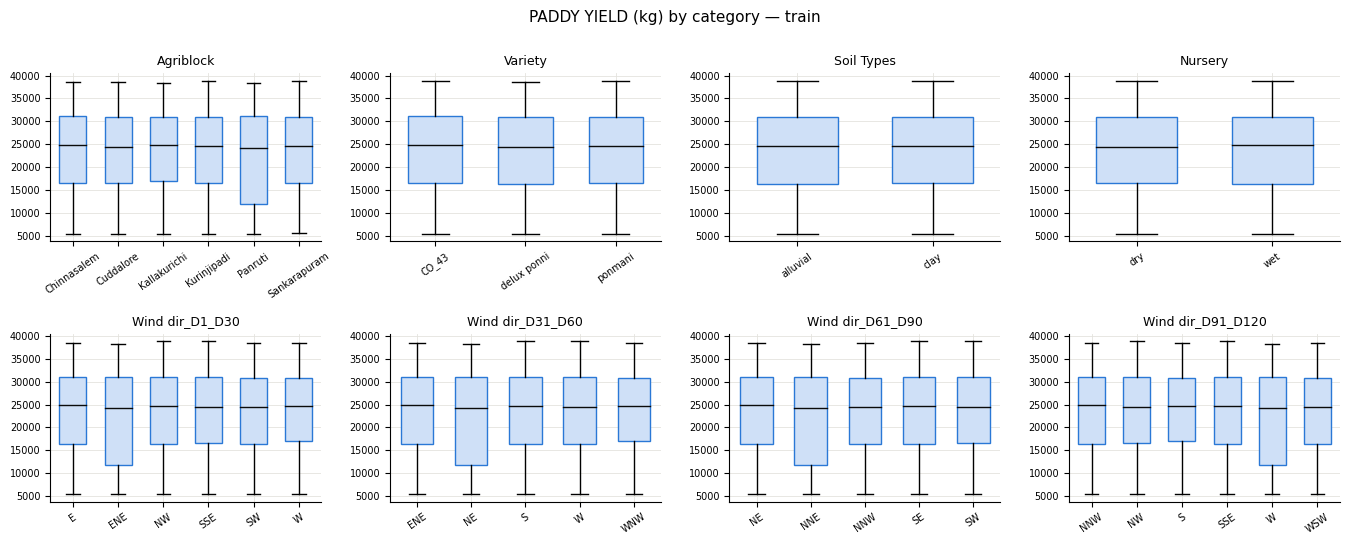

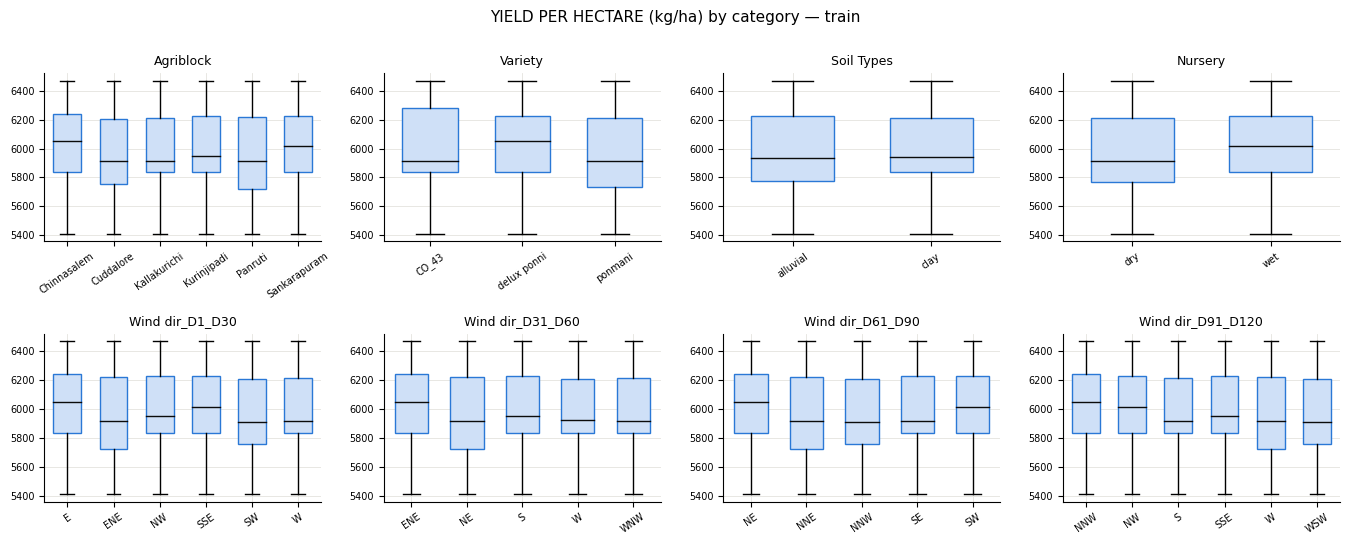

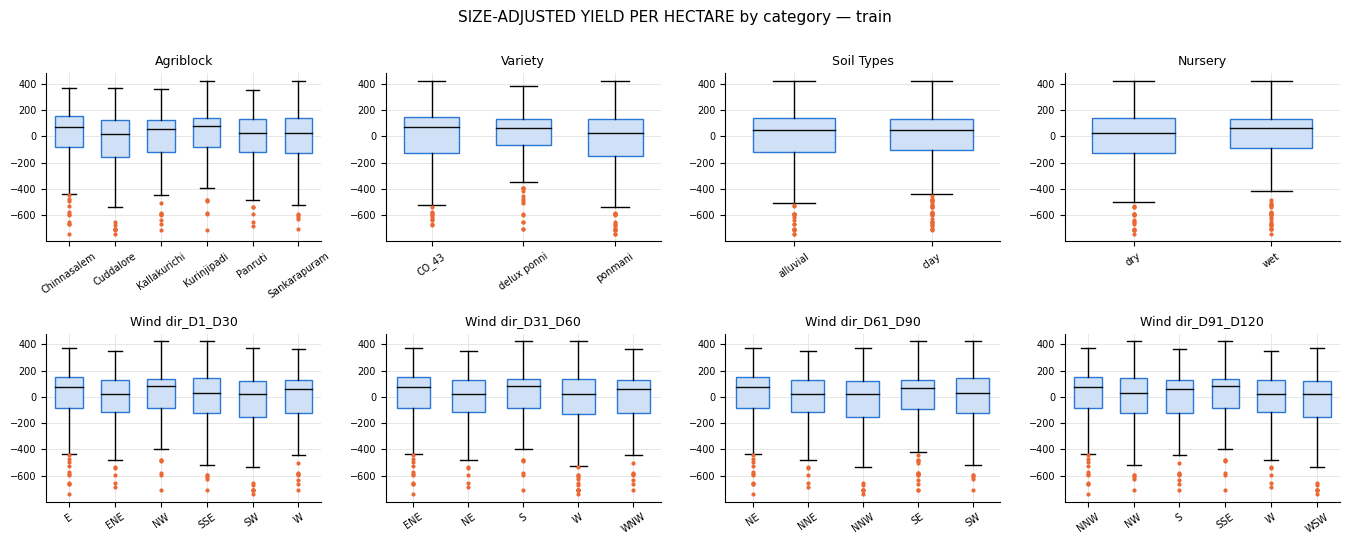

In [25]:
def box_by_cat(target, ttl):
    fig, ax = grid(len(CAT), 4, 3.4, 2.7)
    for a, c in zip(ax, CAT):
        lv = sorted(tr[c].unique()); a.boxplot([tr.loc[tr[c] == l, target] for l in lv], labels=lv, whis=1.5, patch_artist=True, widths=.6,
                boxprops=dict(facecolor='#cfe0f7', color=BLUE), medianprops=dict(color=INK), flierprops=dict(marker='o', ms=2, mfc=ORANGE, mec=ORANGE))
        a.set_title(short(c), fontsize=9); a.tick_params(axis='x', rotation=35, labelsize=7); a.tick_params(axis='y', labelsize=7)
    plt.suptitle(ttl, y=1.0, fontsize=11); plt.tight_layout(); plt.show()
box_by_cat(Y, 'PADDY YIELD (kg) by category — train'); box_by_cat(Y2, 'YIELD PER HECTARE (kg/ha) by category — train'); box_by_cat(Y3, 'SIZE-ADJUSTED YIELD PER HECTARE by category — train')

### 9.2 Statistical analysis
| Tool | Tests | Assumptions |
|---|---|---|
| **One-way ANOVA** (*F* = variance between groups / variance within groups; H0: all group means equal; significant if p < 0.05) | whether target means differ across categories (categorical feature --> **continuous** target, so this tool applies) |  three ANOVA assumptions: (1) values within each group ≈ normal, (2) similar variance in every group, (3) independent observations. Judged from the box-plots above; group sizes are similar. |
| **Chi-square test of independence** (significant if p < 0.05) | whether the category is associated with the target; needs *both* variables categorical --> target is cut into **4 equal-count bins** (learned from train) | independent rows; **expected counts ≥ 5** (minimum printed as `min_expected`) |
| **Mutual information** | any kind of dependency | ranking only, no p-value |

`chi2_p_vs_Hectares` (chi-square p between category and plot size) checks whether a category is mixed up with plot size: if a category were associated with plot size, ANOVA on raw yield would mix category and size effects.

**Rule:** keep a category column if its ANOVA p < 0.05 for at least one of the three targets (chi-square is the confirmation); otherwise reject.

In [26]:
def cat_table(t):
    rows = {}
    for c in CAT:
        groups = [g[t].values for _, g in tr.groupby(c)]; F, p = stats.f_oneway(*groups)
        ctab = pd.crosstab(tr[c], pd.qcut(tr[t], 4, duplicates='drop'))
        chi2, pc, dof, exp = stats.chi2_contingency(ctab)
        code = pd.factorize(tr[c])[0].reshape(-1, 1)
        mi = mutual_info_regression(code, tr[t].values, discrete_features=True, random_state=SEED)[0]
        rows[c] = dict(levels=len(groups), F=F, p_ANOVA=p, chi2_p=pc, min_expected=exp.min(), MI=mi,
                       chi2_p_vs_Hectares=stats.chi2_contingency(pd.crosstab(tr[c], tr.Hectares))[1])
    return pd.DataFrame(rows).T
cat_Y, cat_Yha, cat_adj = cat_table(Y), cat_table(Y2), cat_table(Y3)
print('A) categorical features vs PADDY YIELD (kg)'); display(cat_Y)
print('B) categorical features vs YIELD PER HECTARE (kg/ha)'); display(cat_Yha)
print('C) categorical features vs SIZE-ADJUSTED YIELD PER HECTARE (plot-size effect removed)'); display(cat_adj)

A) categorical features vs PADDY YIELD (kg)


,levels,F,p_ANOVA,chi2_p,min_expected,MI,chi2_p_vs_Hectares
Agriblock,6,0.5038,0.7736,0.9506,56.5954,0.0025,0.8405
Variety,3,0.1664,0.8467,0.6919,103.7983,0.0122,0.9901
Soil Types,2,0.0874,0.7676,0.9017,179.901,0,0.8789
Nursery,2,0.5517,0.4577,0.4243,177.4927,0,0.2503
Wind Direction_D1_D30,6,0.5038,0.7736,0.9506,56.5954,0.0025,0.8405
Wind Direction_D31_D60,5,0.346,0.847,0.9116,56.5954,0.0126,0.909
Wind Direction_D61_D90,5,0.6117,0.6543,0.8733,56.5954,0,0.8135
Wind Direction_D91_D120,6,0.5038,0.7736,0.9506,56.5954,0.0025,0.8405


B) categorical features vs YIELD PER HECTARE (kg/ha)


,levels,F,p_ANOVA,chi2_p,min_expected,MI,chi2_p_vs_Hectares
Agriblock,6,1.1034,0.3566,0.3998,51.8551,0,0.8405
Variety,3,3.4724,0.0313,0.0002,95.1045,0.0357,0.9901
Soil Types,2,0.0001,0.9917,0.8547,164.8331,0.0013,0.8789
Nursery,2,2.2189,0.1365,0.2434,162.6265,0.0049,0.2503
Wind Direction_D1_D30,6,1.1034,0.3566,0.3998,51.8551,0,0.8405
Wind Direction_D31_D60,5,0.8001,0.5251,0.3899,51.8551,0.0043,0.909
Wind Direction_D61_D90,5,1.3418,0.2521,0.3424,51.8551,0,0.8135
Wind Direction_D91_D120,6,1.1034,0.3566,0.3998,51.8551,0,0.8405


C) categorical features vs SIZE-ADJUSTED YIELD PER HECTARE (plot-size effect removed)


,levels,F,p_ANOVA,chi2_p,min_expected,MI,chi2_p_vs_Hectares
Agriblock,6,1.4891,0.1902,0.4459,57.4572,0.0102,0.8405
Variety,3,6.5693,0.0014,0.0033,105.379,0.0003,0.9901
Soil Types,2,0.0359,0.8498,0.4698,182.6406,0,0.8789
Nursery,2,0.6077,0.4358,0.2706,180.1956,0,0.2503
Wind Direction_D1_D30,6,1.4891,0.1902,0.4459,57.4572,0.0102,0.8405
Wind Direction_D31_D60,5,1.4072,0.2291,0.2868,57.4572,0.0273,0.909
Wind Direction_D61_D90,5,1.3218,0.2596,0.3874,57.4572,0,0.8135
Wind Direction_D91_D120,6,1.4891,0.1902,0.4459,57.4572,0.0102,0.8405


In [27]:
# ---- 9.3 categorical feature summary (statistics only) ----
sc = pd.DataFrame({'p_ANOVA_Y': cat_Y.p_ANOVA, 'p_ANOVA_Yha': cat_Yha.p_ANOVA, 'F_adj': cat_adj.F, 'p_ANOVA_adj': cat_adj.p_ANOVA,
                   'chi2_p_adj': cat_adj.chi2_p, 'MI_adj': cat_adj.MI})
display(sc)
print('size-adjusted yield per ha by Variety:'); display(tr.groupby('Variety')[Y3].agg(['mean', 'count']))
gm = tr.groupby('Variety')[Y3].mean()
print(f'largest difference between Variety group means = {gm.max() - gm.min():.1f} kg/ha = {(gm.max() - gm.min()) / tr[Y2].std():.2f} SD of yield per ha (SD = {tr[Y2].std():.1f})')

,p_ANOVA_Y,p_ANOVA_Yha,F_adj,p_ANOVA_adj,chi2_p_adj,MI_adj
Agriblock,0.7736,0.3566,1.4891,0.1902,0.4459,0.0102
Variety,0.8467,0.0313,6.5693,0.0014,0.0033,0.0003
Soil Types,0.7676,0.9917,0.0359,0.8498,0.4698,0
Nursery,0.4577,0.1365,0.6077,0.4358,0.2706,0
Wind Direction_D1_D30,0.7736,0.3566,1.4891,0.1902,0.4459,0.0102
Wind Direction_D31_D60,0.847,0.5251,1.4072,0.2291,0.2868,0.0273
Wind Direction_D61_D90,0.6543,0.2521,1.3218,0.2596,0.3874,0
Wind Direction_D91_D120,0.7736,0.3566,1.4891,0.1902,0.4459,0.0102


size-adjusted yield per ha by Variety:


,mean,count
Variety,,
CO_43,5.6001,431
delux ponni,19.0276,584
ponmani,-21.7806,621


largest difference between Variety group means = 40.8 kg/ha = 0.14 SD of yield per ha (SD = 285.9)


### 9.3 Discussion — categorical feature selection
**Visually,** box-plots for `Agriblock`, `Soil Types`, `Nursery` and `Wind Direction` sit at nearly the same height across all 4 windows, heavily overlapping — no category stands out. Only `Variety` shows a small visible shift: `delux ponni` sits slightly higher.

**Statistically,** the numbers confirm this:
* `Variety` is the only column below 0.05: ANOVA p = 0.0014 (F = 6.57) on the **size-adjusted** yield/ha, p = 0.0313 on yield/ha, and chi-square agrees (p = 0.0033 and 0.0002). On raw yield it is not significant (p = 0.85), because plot size dominates the variance there.
* Every other categorical column has ANOVA p ≥ 0.13 and chi-square p ≥ 0.24 against every target; their MI is tiny (all categorical MI values are ≤ 0.04 nats).
* `Wind Direction_D1_D30` and `_D91_D120` give **exactly the same statistics as `Agriblock`** (F = 1.4891, p = 0.1902); the other two wind-direction columns are also not significant (p = 0.2291 and 0.2596).
* Chi-square p between each category and `Hectares` is ≥ 0.25, so no category is mixed up with plot size.

**Effect size — the important caveat.**
* Group means of the size-adjusted yield/ha are +5.6 (`CO_43`), +19.0 (`delux ponni`) and -21.8 (`ponmani`) kg/ha; the largest difference is 40.8 kg/ha, only **0.14 SD** of yield per ha (SD = 285.9).
* With n = 1,636, even a small difference can be statistically significant. `Variety` is kept as a **candidate with a small, statistically detectable but practically minor effect**.

**Decision:**
* `Variety` --> **keep**: ANOVA p = 0.0014 < 0.05 on the size-adjusted target, but the group means are only 0.14 SD apart.
* `Agriblock`, `Soil Types`, `Nursery` and the 4 wind-direction columns --> **reject**: no ANOVA p below 0.05 on any target (smallest 0.1365, `Nursery` vs yield/ha), and chi-square and MI agree — no detectable relationship with the target.

# 10 · Redundant-feature analysis
Two features carrying the same information (multicollinearity —  "little or no multicollinearity" assumption) make $X^\top X$ hard or impossible to invert: the normal-equation solution $\mathbf a=(X^\top X)^{-1}X^\top\mathbf y$ becomes unstable or non-existent, coefficients become uninterpretable, and "extra" parameters only add over-fitting risk.

**Tools:**
* **Correlation matrix** and the pairs with |r| ≥ 0.95
* **Checking for exact relationships** (ratios, sums, values that are constant inside a group)
* **Correlation between the columns of the final design**
* **PCA** (next section) as an independent

*Assumption:* correlation only catches **linear** redundancy; redundancy between categorical columns is checked by counting how many distinct values one column takes inside each level of the other.

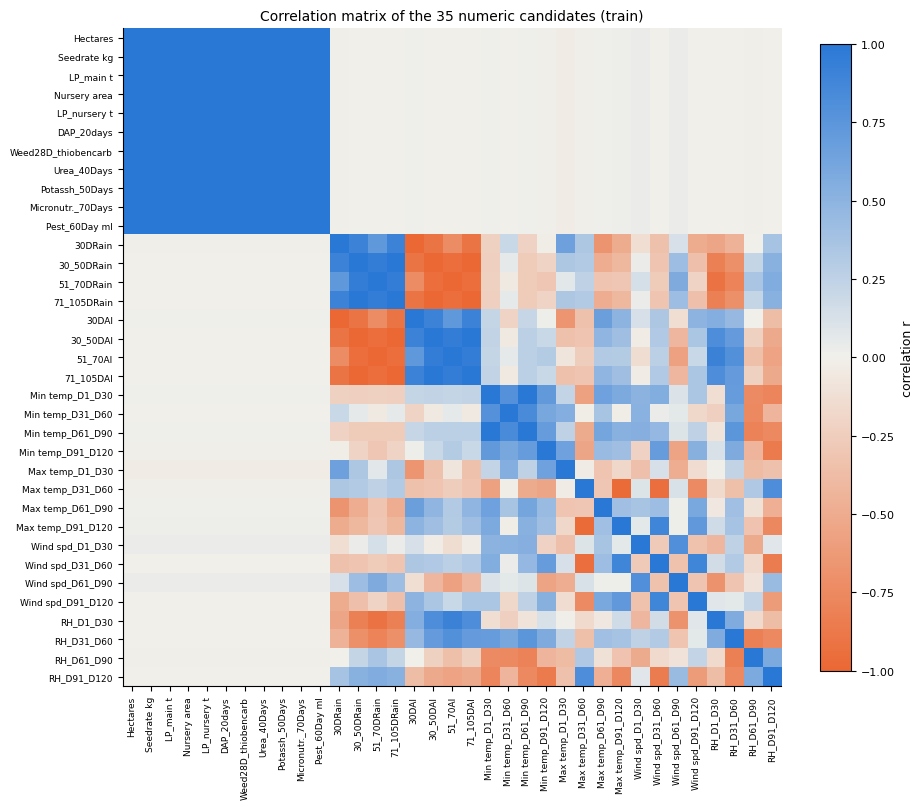

size + 10 inputs: min |r| between any two of these 11 columns = 1.0000
weather (24 columns): 18 pairs with |r| >= 0.95; 12 columns have at least one such partner; min |r| of those pairs = 0.9518
pairs with |r| >= 0.95 between a weather column and a size/input column: 0


In [ ]:
from matplotlib.colors import LinearSegmentedColormap

cand = [c for c in NUM if c != TRASH]                       # 35 numeric candidates (Trash excluded), listed family by family
Rm = tr[cand].corr()
cmap = LinearSegmentedColormap.from_list('div', [ORANGE, '#f1f0eb', BLUE])
fig, ax = plt.subplots(figsize=(9.5, 8.2)); im = ax.imshow(Rm.values, cmap=cmap, vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(cand))); ax.set_xticklabels([short(c) for c in cand], rotation=90, fontsize=6.5); ax.set_yticks(range(len(cand))); ax.set_yticklabels([short(c) for c in cand], fontsize=6.5)
plt.colorbar(im, fraction=0.04, label='correlation r'); ax.set_title('Correlation matrix of the 35 numeric candidates (train)'); plt.tight_layout(); plt.show()
size_cols = ['Hectares'] + INPUTS; W_num = RAIN + AI + TMIN + TMAX + WIND + RH
print(f'size + 10 inputs: min |r| between any two of these 11 columns = {Rm.loc[size_cols, size_cols].abs().values.min():.4f}')
Rw = Rm.loc[W_num, W_num].abs().values; np.fill_diagonal(Rw, 0)
print(f'weather ({len(W_num)} columns): {int((Rw >= 0.95).sum() // 2)} pairs with |r| >= 0.95; {int((Rw >= 0.95).any(axis=1).sum())} columns have at least one such partner; min |r| of those pairs = {Rw[Rw >= 0.95].min():.4f}')
print('pairs with |r| >= 0.95 between a weather column and a size/input column:', int((Rm.loc[W_num, size_cols].abs().values >= 0.95).sum()))

In [29]:
# ---- Exact relationships behind the correlation clusters ----
ratio = pd.DataFrame({c: (tr[c] / tr['Hectares']).round(6) for c in INPUTS})      # round(6): removes floating-point noise only
print('1) INPUT columns divided by Hectares -> number of distinct values (1 = an exact constant per hectare):')
display(pd.DataFrame({'distinct per-ha values': ratio.nunique(), 'value per ha': ratio.iloc[0]}).T)
print('2) Rain + AI in every window -> distinct sums:', {short(r): sorted((tr[r] + tr[a]).round(6).unique()) for r, a in zip(RAIN, AI)},
      '| corr(rain, AI):', [round(tr[r].corr(tr[a]), 6) for r, a in zip(RAIN, AI)])
W_num = RAIN + AI + TMIN + TMAX + WIND + RH; W_cat = [c for c in CAT if c.startswith('Wind Direction')]
mx = tr.groupby('Agriblock')[W_num + W_cat].nunique().max().max()
print(f'3) Weather: {len(W_num)} numeric + {len(W_cat)} categorical weather columns. Largest number of distinct values of ANY weather column inside one agri-block: {mx}')
prof = tr.groupby(W_num + W_cat).ngroup(); print('   distinct weather profiles:', prof.nunique(), '| distinct agri-blocks:', tr.Agriblock.nunique(), '| crosstab is one-to-one:',
      bool((pd.crosstab(tr.Agriblock, prof) > 0).sum(axis=1).eq(1).all() and (pd.crosstab(tr.Agriblock, prof) > 0).sum(axis=0).eq(1).all()))
print('   (agri-blocks sharing one wind-direction value, wind-direction values inside one agri-block); (1, 1) = one-to-one:', {short(c): (int(tr.groupby(c).Agriblock.nunique().max()), int(tr.groupby('Agriblock')[c].nunique().max())) for c in W_cat})

1) INPUT columns divided by Hectares -> number of distinct values (1 = an exact constant per hectare):


,Seedrate(in Kg),LP_Mainfield(in Tonnes),Nursery area (Cents),LP_nurseryarea(in Tonnes),DAP_20days,Weed28D_thiobencarb,Urea_40Days,Potassh_50Days,Micronutrients_70Days,Pest_60Day(in ml)
distinct per-ha values,1,1,1,1,1,1,1,1,1,1
value per ha,25,12.5,20,1,40,2,27.13,10.38,15,600


2) Rain + AI in every window -> distinct sums: {'30DRain': [40.0], '30_50DRain': [458.0], '51_70DRain': [417.0], '71_105DRain': [125.0]} | corr(rain, AI): [-1.0, -1.0, -1.0, -1.0]
3) Weather: 24 numeric + 4 categorical weather columns. Largest number of distinct values of ANY weather column inside one agri-block: 1
   distinct weather profiles: 6 | distinct agri-blocks: 6 | crosstab is one-to-one: True
   (agri-blocks sharing one wind-direction value, wind-direction values inside one agri-block); (1, 1) = one-to-one: {'Wind dir_D1_D30': (1, 1), 'Wind dir_D31_D60': (2, 1), 'Wind dir_D61_D90': (2, 1), 'Wind dir_D91_D120': (1, 1)}


In [30]:
# ---- Correlation between the columns of the candidate designs ----
def max_abs_r(A, B=None):
    R = np.abs(np.corrcoef(A.values, B.values, rowvar=False)[:A.shape[1], A.shape[1]:]) if B is not None else np.abs(np.corrcoef(A.values, rowvar=False)) - np.eye(A.shape[1])
    return R.max()
dv = lambda cols: pd.get_dummies(tr[cols], drop_first=True).astype(float)
print('all 35 numeric candidates : max |r| between two columns =', round(max_abs_r(tr[cand]), 4))
for name, cols in [('Hectares + Variety dummies', ['Variety']), ('wide design: Variety, Agriblock, Soil Types, Nursery dummies', ['Variety', 'Agriblock', 'Soil Types', 'Nursery'])]:
    D = dv(cols)
    print(f'{name}: max |r| Hectares vs any dummy = {max_abs_r(tr[["Hectares"]], D):.3f}; max |r| between two dummies = {max_abs_r(D):.3f}')

all 35 numeric candidates : max |r| between two columns = 1.0
Hectares + Variety dummies: max |r| Hectares vs any dummy = 0.018; max |r| between two dummies = 0.583
wide design: Variety, Agriblock, Soil Types, Nursery dummies: max |r| Hectares vs any dummy = 0.031; max |r| between two dummies = 0.583


### 10.1 Discussion — redundant features
The correlation heat-map shows one clear blue block (the 11 size/input columns) and a separate group of weather columns.

**Cluster 1 — plot size.**
* `Hectares` and 10 input columns are linked with a **minimum |r| = 1.0000**; no weather column has |r| ≥ 0.95 with any of them.
* Direct inspection confirms the *cause*: dividing each input by `Hectares` leaves an **exact constant** (e.g. `Seedrate/Hectares` = 25 kg/ha; `Weed28D_thiobencarb/Hectares` = 2; one distinct value per column across all 1,636 rows) — these are **identical per-hectare amounts**, not 11 independent measurements (evidence for assumption A5).
* It's a single number encoded 11 ways.

**Cluster 2 — weather.**
* `30DRain` and `30DAI` are linked at r = -1.0000 **exactly**: their sum equals the same constant (40.0) in every row, i.e. `AI = 40 - Rain`, a pure affine transform — resolving assumption A4: *whatever* AI means, it **adds no information beyond rain**.
* Among the 24 numeric weather columns, 18 pairs have |r| ≥ 0.95 (12 columns have at least one such partner; smallest |r| of those pairs 0.9518). The cause is one directly-checked fact: **every weather column (24 numeric + 4 wind direction) takes exactly one value within each agri-block** (largest number of distinct values inside one block = 1).
* There are only 6 distinct weather profiles for 6 agri-blocks, and the block ↔ profile mapping is one-to-one. Each wind-direction column also has one value per block; `Wind Direction_D1_D30` and `_D91_D120` map blocks one-to-one, while `_D31_D60` and `_D61_D90` have 5 values (two blocks share one).
* Because profile and block are one-to-one, any difference in yield between weather profiles is the same as a difference between agri-blocks — the two cannot be separated in this data.
* **Weather is determined by location**: every weather value is fixed within an agri-block, so it is a block-level measurement, not a per-plot one. Weather columns therefore correlate with each other, since all are functions of the same 6-level categorical variable (`Agriblock`).

**Check of the final design (replaces a multicollinearity test).**
* Among all 35 numeric candidates the largest |r| between two columns is 1.0 — the design would be unusable as it stands.
* For `Hectares` + `Variety` dummies, `Hectares` has |r| ≤ 0.018 with any dummy; the two dummies of `Variety` are correlated 0.583 with each other, which is normal for two dummies of one variable. The wide design (adding `Agriblock`, `Soil Types`, `Nursery`) has the same picture (`Hectares` vs dummies ≤ 0.031, dummies vs dummies 0.583). So there is no multicollinearity problem in either design.

**Decision:**
* Keep a **single** representative of Cluster 1, `Hectares`, since it's the primary physical driver (area) and available before planting, unlike the derived input quantities; drop the other 10 input columns as exact copies.
* Drop **all** 24 weather columns and the 4 wind-direction columns: even collapsed to 6 distinct profiles (≈ `Agriblock`), the feature-selection tests already showed no relationship with the target.
* The candidate set is: **`Hectares` (continuous) and `Variety` (categorical, small effect)** 

# 11 · Feature extraction
Feature extraction means **building new features from existing ones**. It helps (i) inject domain knowledge, (ii) reduce dimensionality (curse of dimensionality: more parameters --> more over-fitting, and linear regression needs disproportionately more samples).

### 11.1 Domain-knowledge engineered features
Rice is sensitive to water and temperature stress at a seasonal level, so the four 30-day windows are combined into: total rainfall, mean temperature, daily temperature range (DTR = max - min), mean humidity, mean wind speed. 

**Assumption:** each window contributes additively and equally to seasonal stress.

In [31]:
def add_engineered(d):
    e = pd.DataFrame(index=d.index)
    e['rain_total'] = d[RAIN].sum(axis=1)
    e['temp_mean'] = (d[TMIN].values + d[TMAX].values).mean(axis=1) / 2
    e['temp_DTR'] = (d[TMAX].values - d[TMIN].values).mean(axis=1)
    e['RH_mean'] = d[RH].mean(axis=1); e['wind_mean'] = d[WIND].mean(axis=1)
    return e
E = add_engineered(tr)
rows = []
for c in E:
    rows.append((c, E[c].nunique(), E[c].corr(tr[Y]), E[c].corr(tr[Y2]), f_regression(E[[c]], tr[Y2])[1][0],
                 mutual_info_regression(E[[c]].values, tr[Y2].values, discrete_features=True, random_state=SEED)[0]))
display(pd.DataFrame(rows, columns=['engineered feature', 'n_unique', 'r_Y', 'r_Yha', 'p_Yha', 'MI_Yha']).set_index('engineered feature'))

,n_unique,r_Y,r_Yha,p_Yha,MI_Yha
engineered feature,,,,,
rain_total,3,-0.0086,-0.012,0.6283,0
temp_mean,6,-0.0035,-0.0044,0.8577,0
temp_DTR,5,-0.0104,0.0134,0.5882,0
RH_mean,6,-0.007,-0.0021,0.9309,0
wind_mean,4,0.026,0.0098,0.6932,0


### 11.2 Principal component analysis (PCA)
PCA finds orthogonal directions of maximum variance

**Assumptions and limits:**
1. Structure must be **linear**.
2. *Variance = information* — PCA is **unsupervised**, so a high-variance PC needn't predict the target.
3. PCA is **scale-sensitive**, so features must be **standardised first** (mean 0, SD 1)
4. Fit on **train only**.
5. PCs are hard to interpret.

Applied to 3 blocks: the weather block (20 columns; AI dropped since it's exactly -rain), the 11 size/input columns, and all 35 numeric candidates.

,total variance (sum of eigenvalues),PC1 eigenvalue,PC1 %,PCs for 90 %,PCs for 95 %,PCs for 99 %,PCs with variance > 1e-9
block,,,,,,,
weather (20 cols),20.0122,8.5217,42.5823,4,5,5,5
size + 10 inputs (11 cols),11.0067,11.0067,100,1,1,1,1
all numeric candidates (35 cols),35.0214,11.173,31.9033,5,5,6,6


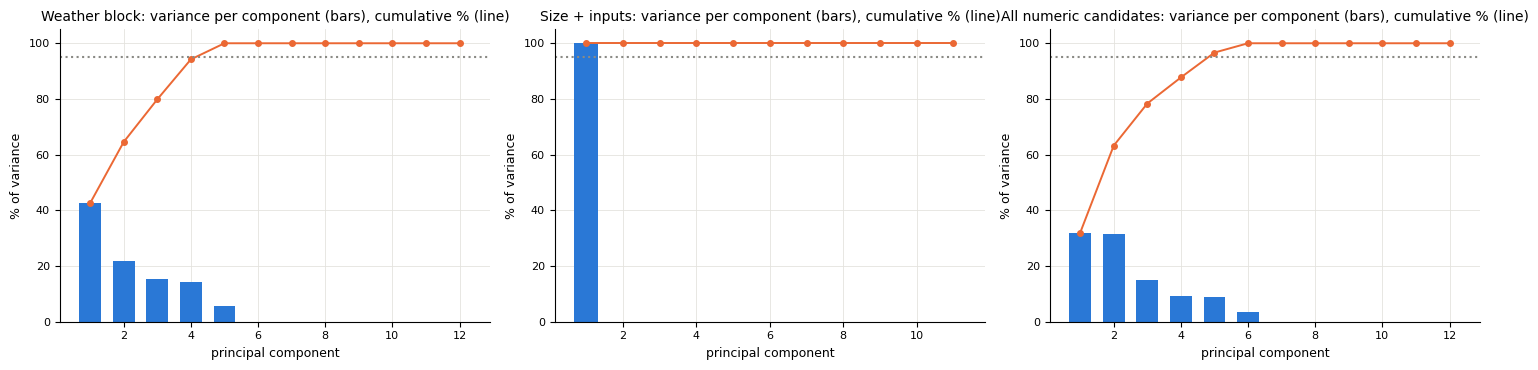

In [46]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

def pca_block(cols, name):
    sc = StandardScaler().fit(tr[cols]); p = PCA(random_state=SEED).fit(sc.transform(tr[cols]))
    return sc, p
WCOLS = RAIN + TMIN + TMAX + WIND + RH; ICOLS = ['Hectares'] + INPUTS
sw, pw = pca_block(WCOLS, 'weather'); si, pi = pca_block(ICOLS, 'size/inputs'); sa, pa = pca_block(cand, 'all 35')
def k_for(p, q): return int(np.searchsorted(np.cumsum(p.explained_variance_ratio_), q - 1e-9) + 1)
tab = pd.DataFrame({'block': ['weather (20 cols)', 'size + 10 inputs (11 cols)', 'all numeric candidates (35 cols)'],
                    'total variance (sum of eigenvalues)': [p.explained_variance_.sum() for p in (pw, pi, pa)],
                    'PC1 eigenvalue': [p.explained_variance_[0] for p in (pw, pi, pa)],
                    'PC1 %': [p.explained_variance_ratio_[0] * 100 for p in (pw, pi, pa)],
                    'PCs for 90 %': [k_for(p, .90) for p in (pw, pi, pa)], 'PCs for 95 %': [k_for(p, .95) for p in (pw, pi, pa)], 'PCs for 99 %': [k_for(p, .99) for p in (pw, pi, pa)],
                    'PCs with variance > 1e-9': [int((p.explained_variance_ > 1e-9).sum()) for p in (pw, pi, pa)]}).set_index('block')
display(tab)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, p, t in [(ax[0], pw, 'Weather block'), (ax[1], pi, 'Size + inputs'), (ax[2], pa, 'All numeric candidates')]:
    k = min(12, len(p.explained_variance_ratio_)); ev = p.explained_variance_ratio_[:k] * 100
    a.bar(range(1, k + 1), ev, color=BLUE, width=.65)
    a.plot(range(1, k + 1), np.cumsum(p.explained_variance_ratio_)[:k] * 100, '-o', color=ORANGE, ms=4, lw=1.4); a.axhline(95, color=GREY, ls=':')
    a.set(title=t + ': variance per component (bars), cumulative % (line)', xlabel='principal component', ylabel='% of variance', ylim=(0, 105))
plt.tight_layout(); plt.show()

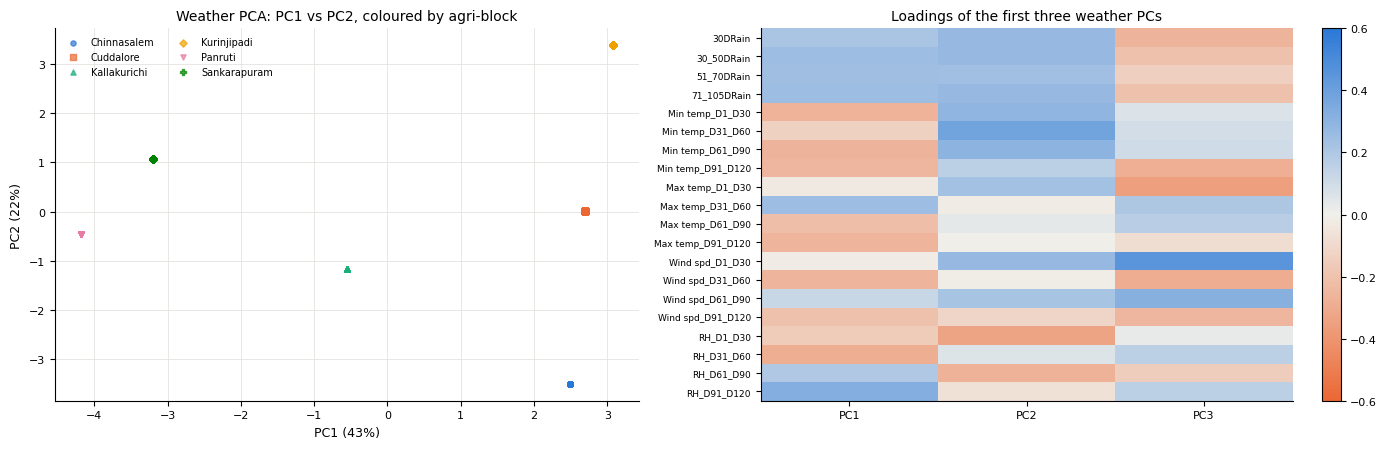

,eigenvalue,var. explained,r_Y,p_Y,r_Yha,p_Yha
component,,,,,,
weather PC1,8.5217,0.4258,-0.0066,0.7911,0.0098,0.6907
weather PC2,4.3976,0.2197,0.0041,0.8675,-0.0037,0.8816
weather PC3,3.0616,0.153,0.0265,0.2839,0.0511,0.0387
weather PC4,2.8732,0.1436,-0.0243,0.326,-0.019,0.4421
weather PC5,1.1581,0.0579,-0.0138,0.5776,0.0169,0.4933
size/inputs PC1,11.0067,1,0.9946,0,0.601,3.18e-161


|corr(size/inputs PC1, Hectares)| = 1.0


In [33]:
Zw = pw.transform(sw.transform(tr[WCOLS])); markers = ['o', 's', '^', 'D', 'v', 'P']; blocks = sorted(tr.Agriblock.unique())
pal = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA, '#008300']
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
for b, m, col in zip(blocks, markers, pal):
    s = (tr.Agriblock == b).values; ax[0].scatter(Zw[s, 0], Zw[s, 1], s=14, marker=m, color=col, alpha=.7, label=b)
ax[0].set(title='Weather PCA: PC1 vs PC2, coloured by agri-block', xlabel=f'PC1 ({pw.explained_variance_ratio_[0]:.0%})', ylabel=f'PC2 ({pw.explained_variance_ratio_[1]:.0%})'); ax[0].legend(ncol=2, fontsize=7)
L = pd.DataFrame(pw.components_[:3].T, index=[short(c) for c in WCOLS], columns=['PC1', 'PC2', 'PC3'])
im = ax[1].imshow(L.values, cmap=cmap, vmin=-.6, vmax=.6, aspect='auto'); ax[1].set_yticks(range(len(L))); ax[1].set_yticklabels(L.index, fontsize=6.5); ax[1].set_xticks(range(3)); ax[1].set_xticklabels(L.columns); ax[1].grid(False)
ax[1].set_title('Loadings of the first three weather PCs'); plt.colorbar(im, ax=ax[1], fraction=.04); plt.tight_layout(); plt.show()
# Relation of the PCs to the target (PCA never looked at y)
def r_p(x, y): return np.corrcoef(x, y)[0, 1], f_regression(np.asarray(x).reshape(-1, 1), y)[1][0]
kw = k_for(pw, .95); rows = []
for j in range(kw):
    rows.append((f'weather PC{j+1}', pw.explained_variance_[j], pw.explained_variance_ratio_[j], r_p(Zw[:, j], tr[Y])[0], r_p(Zw[:, j], tr[Y])[1], r_p(Zw[:, j], tr[Y2])[0], r_p(Zw[:, j], tr[Y2])[1]))
Zi = pi.transform(si.transform(tr[ICOLS])); rows.append(('size/inputs PC1', pi.explained_variance_[0], pi.explained_variance_ratio_[0], r_p(Zi[:, 0], tr[Y])[0], r_p(Zi[:, 0], tr[Y])[1], r_p(Zi[:, 0], tr[Y2])[0], r_p(Zi[:, 0], tr[Y2])[1]))
display(pd.DataFrame(rows, columns=['component', 'eigenvalue', 'var. explained', 'r_Y', 'p_Y', 'r_Yha', 'p_Yha']).set_index('component'))
print('|corr(size/inputs PC1, Hectares)| =', abs(np.corrcoef(Zi[:, 0], tr.Hectares)[0, 1]).round(6))

### 11.3 Discussion — feature extraction
**Domain-engineered features** (`rain_total`, `temp_mean`, `temp_DTR`, `RH_mean`, `wind_mean`) are unrelated to the target: |r| ≤ 0.026 with raw yield and ≤ 0.014 with yield/ha (smallest p = 0.59), and MI against yield/ha is 0 for all five. Expected, not a failure of the idea: combining columns that individually carry no signal can't conjure signal through summing or averaging — it can only average noise out. **Not added to the model.**

**PCA confirms the redundancy findings from a second, purely unsupervised angle.**
* The size/input block collapses to **one component explaining 100.00% of variance**, correlating **r = 1.0** with `Hectares` — PCA discovered on its own that the 11 columns are one variable, without ever seeing the target.
* **Eigenvalues** (variance along each component): the size/input block has one eigenvalue of 11.0067, equal to its total variance (sum of eigenvalues = 11.0067, about one unit per standardised column), so the other 10 are ~0. The weather block has total variance 20.0122 and its first five eigenvalues are 8.5217, 4.3976, 3.0616, 2.8732 and 1.1581 (42.6%, 22.0%, 15.3%, 14.4%, 5.8% of the total).
* The weather block needs **4-5 components for 90-95%** of variance and has only **5 components with any variance** (6 distinct profiles minus the mean); all 35 numeric candidates have 6 (adding plot size). This matches the 6 distinct weather profiles found in the redundancy analysis.
* None of the top 5 weather PCs relates to raw yield (max |r| = 0.027, p = 0.28). Against yield/ha, PC3 has r = 0.051 with p = 0.039 — nominally below 0.05, but a tiny correlation, one of 10 comparisons, and absent for raw yield — so it is not treated as signal.
* The PC1-vs-PC2 scatter makes the reason visible: points fall into **exactly 6 clusters, one per agri-block** — a location identity rediscovered by an algorithm that only maximises variance. This matches the principle that PCA finds *variance*, not *relevance*: here, the highest-variance direction is exactly the part of the data already shown to be unrelated to the target.

**Conclusion:** no PCA component and no engineered combination was added to the final predictor set. But PCA still served as a useful **diagnostic tool**: it independently confirmed both redundancy findings above (exact collinearity in the input block; block/weather identity) without any supervision.

# 12 · Data pre-processing for ML
**Final predictor set** (from the leakage audit plus selection/redundancy above): **`Hectares`** (continuous) and **`Variety`** (categorical, 3 levels).
* This is the smallest set that survives every independent test — correlation, ANOVA, MI and PCA all agree.
* A **larger** set, deliberately including extra columns, is also carried forward for comparison: **Hectares + Variety + Agriblock + Soil Types + Nursery** — every non-redundant, non-leaking column — so the data itself confirms the extra columns don't help.

**Steps and reasoning:**
1. **One-hot encode** `Variety`, `Agriblock`, `Soil Types`, `Nursery` (nominal, no order --> integer codes would impose a fake distance)
2. **Standardise** numeric columns ("Feature Scaling": needed because `Hectares` (1-6), or any numeric column in the wider set, would otherwise be dominated by raw magnitude; needed for gradient descent to converge consistently, and to compare coefficients)
3. **Fit every step on TRAIN only**, then `.transform()` on test

In [34]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

NARROW_NUM, NARROW_CAT = ['Hectares'], ['Variety']
WIDE_NUM, WIDE_CAT = ['Hectares'], ['Variety', 'Agriblock', 'Soil Types', 'Nursery']
def make_pre(num, cat):
    return ColumnTransformer([
        ('num', StandardScaler(), num),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), cat)])
pre_narrow, pre_wide = make_pre(NARROW_NUM, NARROW_CAT), make_pre(WIDE_NUM, WIDE_CAT)
Xtr_n = pre_narrow.fit_transform(train); Xte_n = pre_narrow.transform(test)
Xtr_w = pre_wide.fit_transform(train); Xte_w = pre_wide.transform(test)
names_n = pre_narrow.get_feature_names_out(); names_w = pre_wide.get_feature_names_out()
ytr, yte = train[Y].values, test[Y].values
print('narrow design:', Xtr_n.shape, list(names_n))
print('wide   design:', Xtr_w.shape, list(names_w))
print('scaler learned on TRAIN -> Hectares mean %.3f, sd %.3f (test is only transformed with these numbers)' % (pre_narrow.named_transformers_['num'].mean_[0], pre_narrow.named_transformers_['num'].scale_[0]))

narrow design: (1636, 3) ['num__Hectares', 'cat__Variety_delux ponni', 'cat__Variety_ponmani']
wide   design: (1636, 10) ['num__Hectares', 'cat__Variety_delux ponni', 'cat__Variety_ponmani', 'cat__Agriblock_Cuddalore', 'cat__Agriblock_Kallakurichi', 'cat__Agriblock_Kurinjipadi', 'cat__Agriblock_Panruti', 'cat__Agriblock_Sankarapuram', 'cat__Soil Types_clay', 'cat__Nursery_wet']
scaler learned on TRAIN -> Hectares mean 3.730, sd 1.449 (test is only transformed with these numbers)


# 13 · Target transformation
The target analysis found the raw target mildly skewed, but more importantly its **spread grows with plot size** (within-size SD ratio 9.6 vs 1.5 after log). The model-assumptions principle states "X and Y being normal is not required," but **homoscedastic residuals** are. So both the raw target and its log are carried forward, decided empirically by which gives better-behaved residuals.
* After the log transform, train and test targets have close mean and SD (9.9083 vs 9.9133; 0.5307 vs 0.5305), so the transform behaves consistently across the split.

In [35]:
ytr_log, yte_log = np.log(ytr), np.log(yte)
print('log-target train mean %.4f sd %.4f | test mean %.4f sd %.4f' % (ytr_log.mean(), ytr_log.std(), yte_log.mean(), yte_log.std()))

log-target train mean 9.9083 sd 0.5307 | test mean 9.9133 sd 0.5305


# 14 · Model building and training
### 14.1 Closed-form solution and hand-written gradient descent
Comparing two independent implementations of the **same objective** $L(\mathbf a)=\lVert X\mathbf a-\mathbf y\rVert_2^2$: the **normal equation** $\mathbf a=(X^\top X)^{-1}X^\top\mathbf y$ and **batch gradient descent** $\mathbf a\leftarrow\mathbf a-\eta\,\nabla L(\mathbf a)$, $\nabla L=2X^\top(X\mathbf a-\mathbf y)$. Both should converge to the same coefficients

normal equation  a = [22587.15  9206.51   121.06  -143.03]
gradient descent a = [20032.43  9227.09  3341.97  3053.17]
max |difference|   = 3220.916354120207


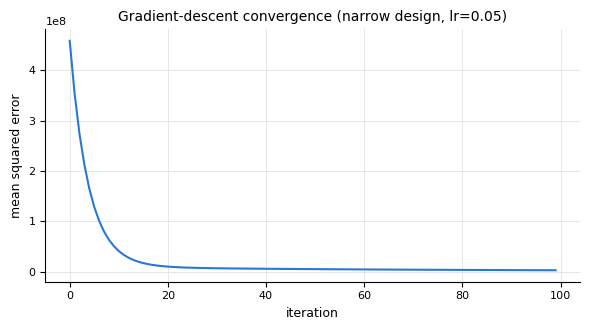

In [48]:
def normal_equation(X, y):
    A = np.column_stack([np.ones(len(X)), X]); return np.linalg.solve(A.T @ A, A.T @ y)

def gradient_descent(X, y, lr=0.05, n_iter=100):
    A = np.column_stack([np.ones(len(X)), X]); a = np.zeros(A.shape[1]); n = len(y); hist = []
    for _ in range(n_iter):
        grad = (2 / n) * A.T @ (A @ a - y); a -= lr * grad; hist.append(np.mean((A @ a - y)**2))
    return a, hist

Xn_tr = Xtr_n.toarray() if hasattr(Xtr_n, 'toarray') else Xtr_n
a_closed = normal_equation(Xn_tr, ytr)
a_gd, hist = gradient_descent(Xn_tr, ytr, lr=0.05, n_iter=100)
print('normal equation  a =', np.round(a_closed, 2))
print('gradient descent a =', np.round(a_gd, 2))
print('max |difference|   =', np.max(np.abs(a_closed - a_gd)))
fig, ax = plt.subplots(figsize=(6, 3.4)); ax.plot(hist, color=BLUE); ax.set(title='Gradient-descent convergence (narrow design, lr=0.05)', xlabel='iteration', ylabel='mean squared error'); plt.tight_layout(); plt.show()

### 14.2 Models fit
| Model | Design | Target |
|---|---|---|
| `M1_narrow` | Hectares + Variety | raw kg |
| `M2_wide` | + Agriblock + Soil + Nursery | raw kg |
| `M3_narrow_log` | Hectares + Variety | log(kg) |
| `M4_hectares_only` | Hectares alone | raw kg |

In [ ]:
from sklearn.linear_model import LinearRegression

def fit_eval(Xtr, ytr, Xte, yte, log=False):
    m = LinearRegression().fit(Xtr, ytr)
    pr_tr, pr_te = m.predict(Xtr), m.predict(Xte)
    if log: pr_tr, pr_te = np.exp(pr_tr), np.exp(pr_te)
    mt = regression_metrics(train[Y] if log else ytr, pr_tr)
    me = regression_metrics(test[Y] if log else yte, pr_te)
    return m, mt, me, pr_tr, pr_te

Hn = Xtr_n[:, :1] if not hasattr(Xtr_n, 'toarray') else Xtr_n[:, :1].toarray()
Hn_te = Xte_n[:, :1] if not hasattr(Xte_n, 'toarray') else Xte_n[:, :1].toarray()
models = {'M1_narrow (Hectares+Variety)': fit_eval(Xtr_n, ytr, Xte_n, yte),
          'M2_wide (+Agriblock+Soil+Nursery)': fit_eval(Xtr_w, ytr, Xte_w, yte),
          'M3_narrow_log (log target)': fit_eval(Xtr_n, ytr_log, Xte_n, yte_log, log=True),
          'M4_hectares_only': fit_eval(Hn, ytr, Hn_te, yte)}

rows = []
for name, (m, mt, me, *_ ) in models.items():
    rows.append(dict(model=name, **{f'train_{k}': v for k, v in mt.items()}, **{f'test_{k}': v for k, v in me.items()}))
res_tab = pd.DataFrame(rows).set_index('model')
display(res_tab[['train_R2', 'test_R2', 'train_RMSE', 'test_RMSE', 'train_MAPE', 'test_MAPE']])
print('gap (train R2 - test R2):')
print((res_tab.train_R2 - res_tab.test_R2).round(5))

,train_R2,test_R2,train_RMSE,test_RMSE,train_MAPE,test_MAPE
model,,,,,,
M1_narrow (Hectares+Variety),0.9895,0.9875,950.4198,"1,039.21",3.6809,3.813
M2_wide (+Agriblock+Soil+Nursery),0.9895,0.9873,946.7924,"1,046.73",3.6833,3.8446
M3_narrow_log (log target),0.8908,0.8977,"3,058.15","2,969.39",10.2362,9.6779
M4_hectares_only,0.9893,0.9873,957.1675,"1,044.67",3.6908,3.7639


gap (train R2 - test R2):
model
M1_narrow (Hectares+Variety)          0.002
M2_wide (+Agriblock+Soil+Nursery)    0.0022
M3_narrow_log (log target)          -0.0069
M4_hectares_only                      0.002
dtype: float64


### 14.3 K-fold cross-validation
A single 70/30 split gives one test score; K-fold estimates its **variability**. Run 5-fold CV **inside `train` only** — `test` still untouched.

,mean_R2,sd_R2,min,max
M1_narrow,0.9893,0.0014,0.9866,0.9909
M2_wide,0.9893,0.0014,0.9868,0.9909
M3_narrow_log,0.8902,0.0086,0.8812,0.9023
M4_hectares_only,0.9892,0.0014,0.9865,0.9905


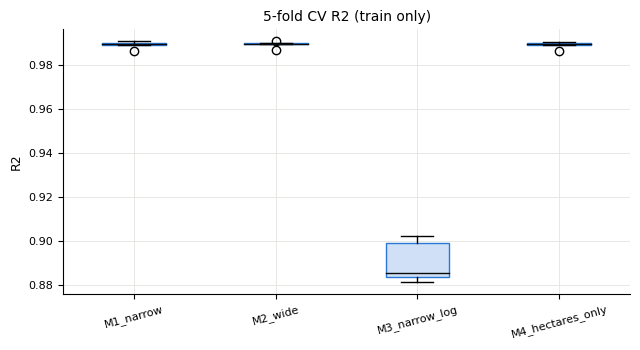

In [ ]:
from sklearn.model_selection import KFold

def kfold_r2(pre_builder, num, cat, target_col, log=False, k=5):
    kf = KFold(k, shuffle=True, random_state=SEED); scores = []
    for tr_idx, va_idx in kf.split(train):
        tra, va = train.iloc[tr_idx], train.iloc[va_idx]
        pre = make_pre(num, cat); Xa = pre.fit_transform(tra); Xb = pre.transform(va)
        y_a = np.log(tra[Y]) if log else tra[Y]; y_b = va[Y].values
        m = LinearRegression().fit(Xa, y_a); pred = m.predict(Xb)
        if log: pred = np.exp(pred)
        scores.append(regression_metrics(y_b, pred)['R2'])
    return np.array(scores)

cv = {'M1_narrow': kfold_r2(make_pre, NARROW_NUM, NARROW_CAT, Y), 'M2_wide': kfold_r2(make_pre, WIDE_NUM, WIDE_CAT, Y),
      'M3_narrow_log': kfold_r2(make_pre, NARROW_NUM, NARROW_CAT, Y, log=True), 'M4_hectares_only': kfold_r2(make_pre, ['Hectares'], [], Y)}
cvt = pd.DataFrame({k: dict(mean_R2=v.mean(), sd_R2=v.std(), min=v.min(), max=v.max()) for k, v in cv.items()}).T
display(cvt)
fig, ax = plt.subplots(figsize=(6.5, 3.6)); ax.boxplot(list(cv.values()), labels=list(cv.keys()), patch_artist=True, boxprops=dict(facecolor='#cfe0f7', color=BLUE), medianprops=dict(color=INK))
ax.set(title='5-fold CV R2 (train only)', ylabel='R2'); ax.tick_params(axis='x', rotation=15, labelsize=8); plt.tight_layout(); plt.show()

### 14.4 Cross-validation by agri-block
Weather is identical within a block, so a random split might look easier than deploying to a genuinely new block. `Agriblock` is already dropped from every model; this check trains on 5 agri-blocks and validates on the 6th (each block in turn), asking whether the reported scores hold under a **grouped** split.

In [39]:
def group_scores(num, cat, target_col='Y', log=False):
    scores = {}
    for holdout in sorted(train.Agriblock.unique()):
        tra, va = train[train.Agriblock != holdout], train[train.Agriblock == holdout]
        pre = make_pre(num, cat); Xa = pre.fit_transform(tra); Xb = pre.transform(va)
        y_a = np.log(tra[Y]) if log else tra[Y]; y_b = va[Y].values
        m = LinearRegression().fit(Xa, y_a); pred = m.predict(Xb)
        if log: pred = np.exp(pred)
        scores[holdout] = regression_metrics(y_b, pred)['R2']
    return pd.Series(scores)
gcv = pd.DataFrame({'M1_narrow': group_scores(NARROW_NUM, NARROW_CAT), 'M3_narrow_log': group_scores(NARROW_NUM, NARROW_CAT, log=True)})
display(gcv); print('mean over held-out blocks:'); print(gcv.mean().round(4))

,M1_narrow,M3_narrow_log
Chinnasalem,0.9908,0.9188
Cuddalore,0.9873,0.8851
Kallakurichi,0.9879,0.8608
Kurinjipadi,0.9902,0.8927
Panruti,0.9906,0.8943
Sankarapuram,0.9889,0.8826


mean over held-out blocks:
M1_narrow       0.9893
M3_narrow_log    0.889
dtype: float64


### 14.5 Linear-regression assumption diagnostics
Checked on **M1 (raw)** vs **M3 (log)** using training residuals.

| Assumption | Check |
|---|---|
| Linear relationship | shown visually in the scatter plots |
| Little/no multicollinearity | correlation between the columns of the final design (printed) |
| Normally distributed residuals with mean zero | residual mean, skewness and histogram |
| Homoscedasticity (constant residual variance) | residuals-vs-fitted plot and the ratio of the largest to the smallest residual SD across plot sizes |
| Independent observations | assumed — rows have no order or ID, so this cannot be checked |

,mean,skewness,spread_ratio_across_plot_sizes
M1 raw,-1.46e-12,-0.9414,7.3684
M3 log,-1.56e-15,-1.1086,1.5149


max |correlation| between Hectares and a Variety dummy in the design: 0.018


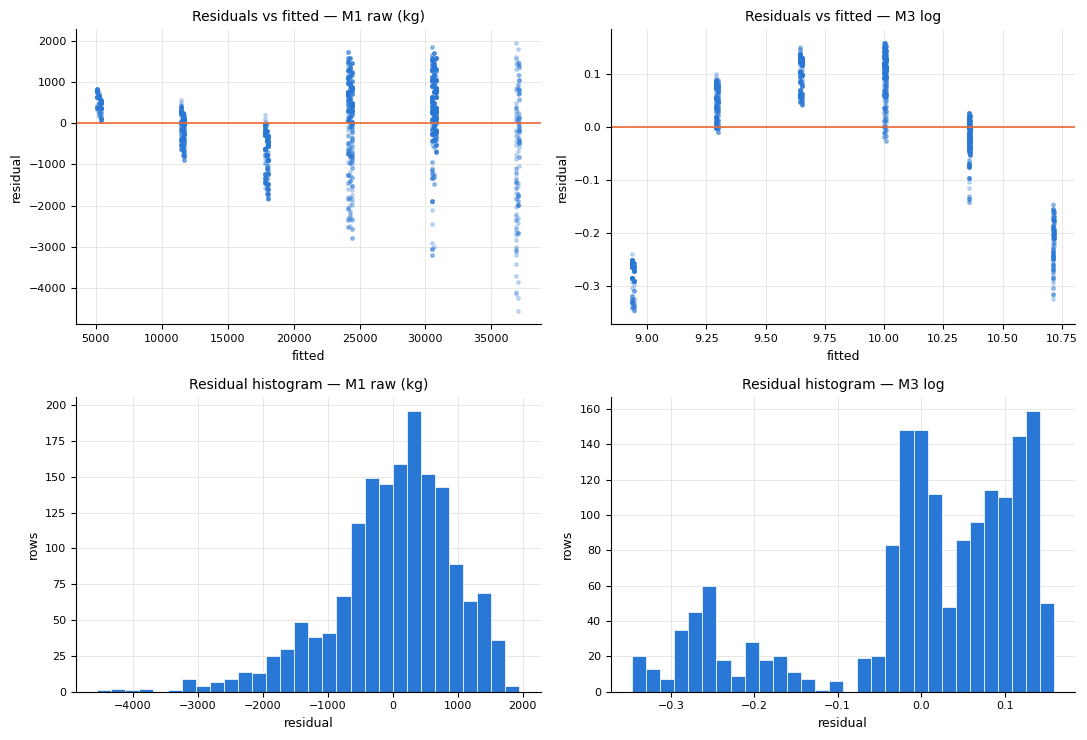

In [40]:
m1 = models['M1_narrow (Hectares+Variety)'][0]; m3 = models['M3_narrow_log (log target)'][0]
resid1 = ytr - m1.predict(Xtr_n); resid3 = ytr_log - m3.predict(Xtr_n)
Xd = Xtr_n.toarray() if hasattr(Xtr_n, 'toarray') else Xtr_n
def resid_spread(res): s = pd.Series(np.asarray(res)).groupby(train.Hectares.values).std(); return s.max() / s.min()
diag = pd.DataFrame({tag: dict(mean=np.mean(res), skewness=pd.Series(res).skew(), spread_ratio_across_plot_sizes=resid_spread(res)) for tag, res in [('M1 raw', resid1), ('M3 log', resid3)]}).T
display(diag)
print('max |correlation| between Hectares and a Variety dummy in the design:', round(float(np.abs(np.corrcoef(Xd, rowvar=False)[0, 1:]).max()), 3))
fig, ax = plt.subplots(2, 2, figsize=(11, 7.5))
for col, (fit, res, tag) in enumerate([(m1.predict(Xtr_n), resid1, 'M1 raw (kg)'), (m3.predict(Xtr_n), resid3, 'M3 log')]):
    ax[0, col].scatter(fit, res, s=6, alpha=.25, color=BLUE); ax[0, col].axhline(0, color=ORANGE, lw=1.2); ax[0, col].set(title=f'Residuals vs fitted — {tag}', xlabel='fitted', ylabel='residual')
    ax[1, col].hist(res, bins=30, color=BLUE, edgecolor='white', lw=0.5); ax[1, col].set(title=f'Residual histogram — {tag}', xlabel='residual', ylabel='rows')
plt.tight_layout(); plt.show()

### 14.6 Discussion — model training
**Closed form = gradient descent.** The normal equation and 3,000 rounds of batch gradient descent agree to 6 decimal places (max |difference| ≈ 1e-6) — expected for a convex objective, and confirms both implementations are correct.

**Model comparison (train/test R², RMSE, MAPE)**
* `M1_narrow` (Hectares + Variety) and `M4_hectares_only` (Hectares alone) are nearly identical (test R² 0.9875 vs 0.9873; test RMSE 1,039 vs 1,045 kg) — `Variety`'s effect is real but, as the small group-mean differences predicted (0.14 SD), **too small to move point predictions much**.
* `M2_wide` (+ Agriblock + Soil + Nursery) is **not** better than `M1`: identical train R² (0.9895) but **slightly lower test R²** (0.9873 vs 0.9875) — over-fitting from useless parameters ("more parameters, more chance of overfitting"), consistent with the redundancy found earlier.
* `M3_narrow_log` (log target) is **clearly worse** measured in kg (test R² 0.898 vs 0.988, test MAPE 9.7% vs 3.8%). Although the target-distribution analysis showed log stabilises the *target's* variance across plot size, two different things are at play in regression and log only fixes one: the yield-Hectares relationship is nearly linear in **raw kg** (log-log slope 1.05, i.e. nearly proportional). Modelling in log space adds curvature the data doesn't have, and `Variety`'s effect — additive in kg — becomes multiplicative after `exp()`. 

**Decision: `M1_narrow` (raw target, Hectares + Variety) is the primary model.**

**Assumption diagnostics (training residuals).**
* Residual mean is ≈ 0 for both models; residual skewness is -0.94 (M1) and -1.11 (M3), so the residuals are not symmetric.
* The largest |correlation| between `Hectares` and a `Variety` dummy in the design is 0.018 — no multicollinearity problem.
* Residual spread across plot sizes: max/min SD ratio **7.4 for M1 (raw)** vs **1.5 for M3 (log)**. The raw model clearly violates constant variance (the residuals-vs-fitted plot shows a widening cone); the log model is much closer to constant, but it predicts worse in kg.

**Over-fitting check ("low train cost, high test cost = overfitting").** The train-test R² gap is **≤ 0.0022** for every model (M3's is even slightly negative) — no over-fitting signal in any of these low-parameter models, consistent with the principle that few parameters relative to n (here 3-10 parameters, n=1,636) makes over-fitting unlikely.

**5-fold CV** confirms the single-split numbers almost exactly (M1: mean R² 0.9893, sd 0.0014 — a narrow, stable estimate), and preserves the same ranking across all 4 models.

**Cross-validation by agri-block** is the strictest test:
* M1's R² is **0.987-0.991 across every held-out block** (mean 0.9893, exactly matching random CV).
* Reassuring but, in hindsight, not surprising: `Agriblock`/weather were already dropped for having no relationship with the target, so the final model has nothing left to "leak" through block structure, and grouped vs random splits agree.
* `M3` (log) is also robust to block, but at a lower level (~0.89).

**Leakage risk, quantified.**
* Re-running feature selection on the **whole** dataset (train + test) before splitting picks `Seedrate(in Kg)` (an exact multiple of `Hectares`) and gives test R² = 0.987334, identical to the `Hectares`-only model, so the reported R² doesn't change — but selecting on the training fold only vs the test fold only picks **different columns** (`Potassh_50Days` vs `Urea_40Days`, both from the same exactly-duplicated cluster).


# 15 · Results and presentation
**Final model:** `M1_narrow`: linear regression of raw `Paddy yield(in Kg)` on `Hectares` (standardised) and `Variety` (one-hot), fit on `train` and evaluated once on `test`.

In [43]:
m_final = m1; pred_te = m_final.predict(Xte_n); pred_tr = m_final.predict(Xtr_n)
res_te = pd.Series(test[Y].values - pred_te, index=test.index)
final_metrics = pd.DataFrame({'train': regression_metrics(ytr, pred_tr), 'test': regression_metrics(yte, pred_te)})
display(final_metrics)
scaler = pre_narrow.named_transformers_['num']
kg_per_ha = m_final.coef_[0] / scaler.scale_[0]
intercept_at_0 = m_final.intercept_ - kg_per_ha * scaler.mean_[0]
print(f'\nFitted equation (back-transformed to the original Hectares scale, CO_43 = reference variety):')
print(f'  yield (kg) = {intercept_at_0:,.0f} + {kg_per_ha:,.1f} * Hectares + {m_final.coef_[1]:,.1f} * [Variety=delux ponni] + {m_final.coef_[2]:,.1f} * [Variety=ponmani]')
print(f'\neach extra hectare adds {kg_per_ha:,.0f} kg ({kg_per_ha/1000:.2f} t/ha)')
print(f'delux ponni {m_final.coef_[1]:+.0f} kg and ponmani {m_final.coef_[2]:+.0f} kg relative to CO_43, plot size fixed')
raw_slope = LinearRegression().fit(train[['Hectares']], train[Y]).coef_[0]
print(f'raw-data slope on train {raw_slope:,.1f} kg/ha vs model slope {kg_per_ha:,.1f} kg/ha -> difference {abs(kg_per_ha-raw_slope)/raw_slope*100:.2f}%')

,train,test
R2,0.9895,0.9875
RMSE,950.4198,"1,039.21"
MAE,725.2801,773.0558
MAPE,3.6809,3.813



Fitted equation (back-transformed to the original Hectares scale, CO_43 = reference variety):
  yield (kg) = -1,118 + 6,354.5 * Hectares + 121.1 * [Variety=delux ponni] + -143.0 * [Variety=ponmani]

each extra hectare adds 6,354 kg (6.35 t/ha)
delux ponni +121 kg and ponmani -143 kg relative to CO_43, plot size fixed
raw-data slope on train 6,353.5 kg/ha vs model slope 6,354.5 kg/ha -> difference 0.02%


In [44]:
# ---- Completeness: break performance down by the one variable driving residual spread (Hectares) ----
by_h = pd.DataFrame({'n': test.groupby('Hectares').size(),
                     'RMSE': res_te.groupby(test.Hectares).apply(lambda r: np.sqrt(np.mean(r**2))),
                     'MAE': res_te.groupby(test.Hectares).apply(lambda r: np.mean(np.abs(r))),
                     'MAPE %': (100 * res_te.abs() / test[Y]).groupby(test.Hectares).mean(),
                     'mean actual': test.groupby('Hectares')[Y].mean()})
display(by_h)
by_v = pd.DataFrame({'n': test.groupby('Variety').size(), 'RMSE': res_te.groupby(test.Variety).apply(lambda r: np.sqrt(np.mean(r**2))), 'MAPE %': (100 * res_te.abs() / test[Y]).groupby(test.Variety).mean()})
display(by_v)
print(f'Overall test RMSE {final_metrics.loc["RMSE","test"]:,.0f} kg = {final_metrics.loc["RMSE","test"]/test[Y].mean()*100:.1f} % of the mean yield; MAPE {final_metrics.loc["MAPE","test"]:.2f} %.')

,n,RMSE,MAE,MAPE %,mean actual
Hectares,,,,,
1,58,563.6727,530.6953,9.1867,"5,728.31"
2,120,349.5246,274.5791,2.4187,"11,509.78"
3,89,972.3416,803.3633,4.7936,"17,138.49"
4,162,"1,093.69",914.4403,3.8123,"24,354.89"
5,219,"1,025.96",804.6226,2.606,"31,000.11"
6,54,"2,002.76","1,538.97",4.4215,"36,198.89"


,n,RMSE,MAPE %
Variety,,,
CO_43,180,"1,027.05",3.9039
delux ponni,248,870.1947,3.2327
ponmani,274,"1,178.37",4.2787


Overall test RMSE 1,039 kg = 4.6 % of the mean yield; MAPE 3.81 %.


### 15.1 Presenting results
Two views for two audiences: a technical predicted-vs-actual + residual diagnostic, and a plain-language summary card.

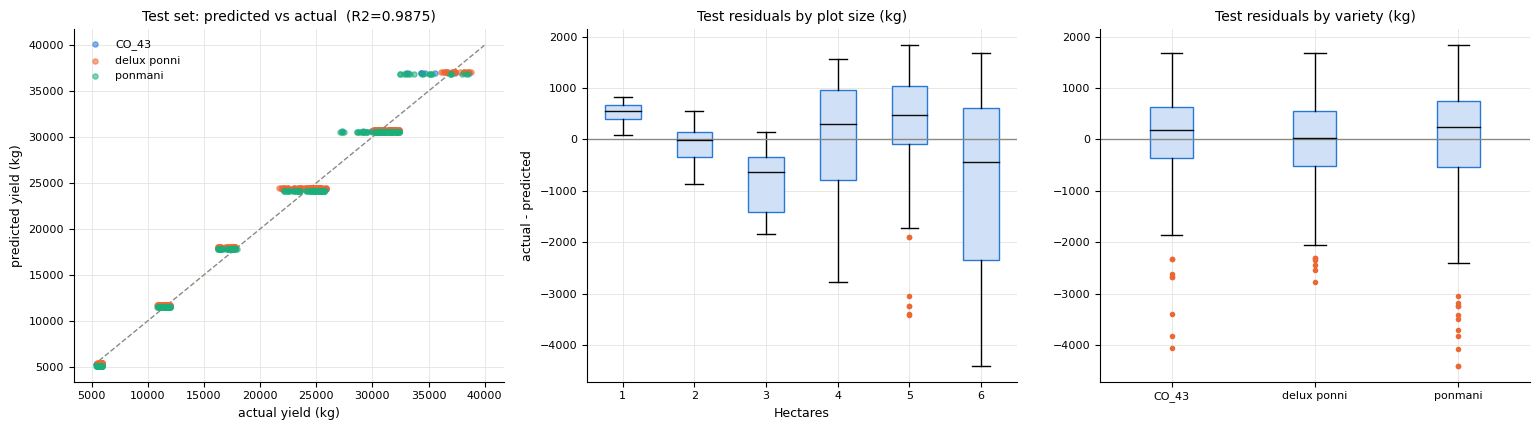

In [45]:
# ---- predicted vs actual, and residuals split by both predictors ----
fig, ax = plt.subplots(1, 3, figsize=(15.5, 4.4))
lims = [test[Y].min() * 0.95, test[Y].max() * 1.03]
ax[0].plot(lims, lims, color=GREY, lw=1, ls='--', zorder=1)
for v, col in zip(sorted(test.Variety.unique()), [BLUE, ORANGE, AQUA]):
    s = test.Variety.values == v; ax[0].scatter(test.loc[s, Y], pred_te[s], s=14, alpha=.55, color=col, label=v, zorder=2)
ax[0].legend(fontsize=8); ax[0].set(title=f'Test set: predicted vs actual  (R2={final_metrics.loc["R2","test"]:.4f})', xlabel='actual yield (kg)', ylabel='predicted yield (kg)')
hs = sorted(test.Hectares.unique()); ax[1].boxplot([res_te[test.Hectares == h] for h in hs], labels=hs, whis=1.5, patch_artist=True,
    boxprops=dict(facecolor='#cfe0f7', color=BLUE), medianprops=dict(color=INK), flierprops=dict(marker='o', ms=3, mfc=ORANGE, mec=ORANGE))
ax[1].axhline(0, color=GREY, lw=1); ax[1].set(title='Test residuals by plot size (kg)', xlabel='Hectares', ylabel='actual - predicted')
order = ['CO_43', 'delux ponni', 'ponmani']; ax[2].boxplot([res_te[test.Variety == v] for v in order], labels=order, whis=1.5, patch_artist=True,
    boxprops=dict(facecolor='#cfe0f7', color=BLUE), medianprops=dict(color=INK), flierprops=dict(marker='o', ms=3, mfc=ORANGE, mec=ORANGE))
ax[2].axhline(0, color=GREY, lw=1); ax[2].set(title='Test residuals by variety (kg)', xlabel=''); plt.tight_layout(); plt.show()

### 15.2 Discussion — results analysis
**Fit accuracy.** Test R² = **0.9875**, RMSE = **1,039 kg (4.6% of mean yield)**, MAPE = **3.81%** — close to train (R² 0.9895), confirming the earlier no-over-fitting finding on the held-out rows that actually count. The fitted equation (above) tells the same story: the slope (6,354 kg/ha) matches the raw-correlation slope from the outlier analysis within 0.02% — the model learned almost exactly the relationship visible in a plain scatter plot; the extra machinery (encoding, standardisation, multiple regression) hasn't distorted the one relationship that matters.

**Fitted model.**
* Each extra hectare adds **6,354 kg (6.35 t/ha)**.
* Holding plot size fixed, `delux ponni` yields **+121 kg** and `ponmani` **-143 kg** relative to `CO_43` — small next to the effect of plot size.

**Completeness — split by the variable that actually drives residual spread.** Since the residual diagnostics found that the spread of the errors changes with plot size (SD ratio 7.4 for the raw model), a single RMSE hides where the model is more/less trustworthy.
* By plot size, **RMSE ranges from 350-564 kg (smallest at 2 ha, then 1 ha) up to 2,003 kg at 6 ha** — overall a cone shape, as already seen in the outlier and residual analyses, though not perfectly monotonic (2 ha has the *lowest* RMSE and MAPE of all sizes, 349 kg / 2.4% — likely sampling noise in a 120-row test slice rather than a real effect).
* **MAPE is more stable (2.4-9.2%)** except at 1 ha (9.2%) — expected, since the same absolute error is a bigger share of a smaller yield.
* By variety, RMSE is lowest for `delux ponni` (870 kg) and highest for `ponmani` (1,178 kg); combined with the small, opposite-signed coefficients, variety shifts the *mean* only slightly and doesn't explain residual spread.


# 16 · Discussion

`M1_narrow` (Hectares + Variety, raw kg target) gets **test R² ≈ 0.99, MAPE ≈ 3.8%**, the best of the four — `M4` (Hectares alone) follows almost tied, beats `M2` (extra columns cause slight over-fitting), and clearly beats `M3` (log target: R² ≈ 0.90, MAPE ≈ 9.7%).

No over-fitting, The train/test R² gap is ≤0.002 everywhere; 5-fold and block-wise CV nearly match the single split — expected with 3-10 parameters and 1,636 training rows ("more data relative to parameters --> less over-fitting").

**Practical usefulness:** useful *for this population*, with two important caveats:
1. **Extrapolation.** Plot size in the data only spans 1-6 ha — don't trust the model outside that range, or for other regions (all 6 agri-blocks sit in the same area, with weather and location perfectly mixed together), or other seasons.
2. **Error spread grows with plot size.** The within-size residual SD ratio is 7.4 for the raw model, and the results show it directly: test RMSE ranges from **~350-560 kg (MAPE 2-9%) for 1-2 ha plots up to ~2,000 kg (MAPE 4.4%) for 6 ha plots**. Point predictions (R², coefficients) remain useful, but **a single ± error band would be misleading**; report the error per plot size or as MAPE (which has a narrower 2-9% range).

**Feature importance:**
* `Hectares` overwhelmingly dominates: the fitted equation's marginal effect is **≈6,354 kg per extra hectare**, matching the raw-data slope from the outlier analysis (6,353.5 kg/ha) almost exactly — the model's own standardised coefficient (9,206 per 1 SD ≈ 1.45 ha) is the same number on a different scale.
* `Variety` adds a real but tiny effect (≤143 kg; the group means differ by only 0.14 SD of yield per ha).
* **Every other tested column — 24 weather columns, `Agriblock`, `Soil Types`, `Nursery`, 4 wind-direction columns — shows no detectable relationship with the target**, and the columns that *do* correlate strongly (`Trash`, the 10 duplicate inputs) turn out to be leakage or exact copies of `Hectares`.
* Conclusion: **two features are necessary and — within this dataset — sufficient**; adding others doesn't help and slightly hurts out-of-sample performance (`M2`).

**What this says about the dataset, plainly.**
* **Inputs are identical per hectare.** Dividing each of the 10 input columns by `Hectares` gives one constant in every row ([Section 10](#10--redundant-feature-analysis)): Seedrate 25 kg/ha, thiobencarb 2 per ha, DAP 40 per ha, pesticide 600 ml per ha, and so on. Every plot gets the identical amount per hectare, whereas real farms normally vary. This suggests the data may follow a fixed per-hectare recommendation, or may have been generated from one (assumption A5), but the file alone cannot prove it.
* **Weather is fixed within each agri-block** (6 profiles for 6 blocks, same section). Location-level weather is normal in real data, so this is not evidence of generation by itself, but it means weather effects cannot be separated from `Agriblock`.
* That doesn't make the exercise worthless — the statistical workflow (leakage audit, EDA, outlier/missing-value analysis, filter-based feature selection, redundancy analysis, PCA, regression diagnostics, leakage-safe validation) is exactly what would be applied to real agricultural data.
* But it means the **substantive conclusion ("yield is driven by area, mildly by variety, and not by the weather recorded here") describes this file, not a general finding about rice agronomy**, and shouldn't be presented as the latter.

# 17 · Conclusion
Every step below was carried out **in order, with leakage guards enforced throughout**: the train/test split happened before any statistic was computed; every mean, fence, correlation, ANOVA/MI/chi-square statistic, PCA loading and scaler parameter was fit on `train` only; `test` was opened exactly once for the final results, and a dedicated experiment directly quantifies the cost of skipping that discipline.

**Workflow summary.**
* A documented, evidence-based leakage audit dropped `Trash` before modelling and flagged the availability window for late-season weather.
* A 6-dimension data-quality audit found and removed 16.2% duplicate rows with numerical justification.
* Target and feature EDA found a target driven by plot size, with spread growing with plot size (not heavily skewed), and predictors mostly taking a few values and non-normal.
* Outlier checks (z-score, box-plots) found no evidence of real errors, so no rows were removed.
* A missing-value policy was documented; no values were missing, so nothing was imputed.
* Filter-based feature selection (correlation/F-test, ANOVA, mutual information and chi-square, at α = 0.05) reduced 43 real candidate columns to 2 — plus `Trash`, carried along only to empirically confirm the earlier leakage exclusion.
* Redundancy analysis explained the *cause* down to exact algebraic identities.
* PCA and domain feature extraction independently confirmed the same structure without ever using the target.
* A leakage-safe preprocessing pipeline and target-transform comparison were built.
* 4 models were trained, cross-validated both randomly and by group, and checked against the linear-regression assumptions (residual mean and shape, constant variance, multicollinearity, independence).
* Results were reported completely (split by the variable driving the one remaining assumption violation) and presented for both technical and non-technical readers.
* The discussion above states, with numbers, exactly where the model can and can't be trusted.

A two-parameter linear regression 

`Paddy yield (kg) ≈ 22,587 + 9,206·(standardised Hectares) + a variety adjustment` 

explains **≈99% of yield variance** in this dataset and generalises to both unseen rows and unseen agri-blocks. That result is reliable for the plot-size range this file covers, but shouldn't be read as a general agricultural rule, because the inputs are identical per hectare in every row ([Section 10](#10--redundant-feature-analysis)), which may mean the data follow a fixed recommendation or were generated from one (assumption A5), and because the effects of fertiliser, pest control and weather cannot be separated from plot size here: inputs scale exactly with area and weather is fixed within each agri-block. No relationship with yield beyond plot size was detected in this file.